# Canonicalização de árvores simbólicas

Este experimento compara três estratégias no vocabulário atual do projeto e separa cuidadosamente **forma sintática**, **forma algébrica** e **equivalência observada por execução**.

## Vocabulário e restrições comuns

O vocabulário mantido é exatamente `Parameter`, `Time`, `Lag`, `Add`, `Multiply` e `Tanh`. Nenhum operador foi removido da fase simbólica. Como a AST não possui literais `0` e `1`, subtração, divisão ou potência, regras desses operadores presentes no SimpliPy original não são aplicáveis aqui. Na fase de rollout do método Verifier-Guided, a restrição é declarada: apenas recorrências escalares com `Lag(variable=0, ...)` são executadas; ASTs multivariadas continuam aceitas pela canonização simbólica.

As três implementações estão nas respectivas subpastas deste experimento. A implementação SimpliPy é uma adaptação local e restrita, não o pacote oficial: o projeto usa Python 3.11, enquanto a versão oficial consultada exige Python ≥3.12. O artigo Verifier-Guided afirma que canoniza antes do pooling, mas não publica o algoritmo dessa canonização; aqui usamos AC estrutural e implementamos a etapa distintiva do método, a deduplicação empírica por múltiplos rollouts.

In [1]:
from __future__ import annotations

from functools import reduce
from importlib.util import module_from_spec, spec_from_file_location
from pathlib import Path
from time import perf_counter
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "src" / "tsfmxai").is_dir():
            return candidate
    raise RuntimeError("Repository root not found.")


REPO_ROOT = find_repo_root(Path.cwd().resolve())
EXPERIMENT_ROOT = REPO_ROOT / "experiments" / "canonicalization"

import sys
sys.path.insert(0, str(REPO_ROOT / "src"))

from tsfmxai.representations.expression import (
    Add, Lag, Multiply, Parameter, Tanh, Time, node_count, to_skeleton_formula
)


def load_method(name: str, relative_path: str):
    spec = spec_from_file_location(name, EXPERIMENT_ROOT / relative_path)
    module = module_from_spec(spec)
    sys.modules[name] = module
    assert spec.loader is not None
    spec.loader.exec_module(module)
    return module


ccbl = load_method("experiment_ccbl", "binary_local_commutative/canonicalizer.py")
simplipy = load_method("experiment_simplipy", "simplipy_flash_ansr/canonicalizer.py")
verifier = load_method("experiment_verifier", "verifier_guided/canonicalizer.py")

print(f"Repository: {REPO_ROOT}")
print(f"Python: {platform.python_version()} | Platform: {platform.platform()}")
print(ccbl.METHOD_NAME)
print(simplipy.METHOD_NAME)
print(verifier.METHOD_NAME)

Repository: C:\Users\mateu\repos\tsfmxai
Python: 3.11.9 | Platform: Windows-10-10.0.19045-SP0
CCBL: binary local commutativity + preorder slot relabeling
SimpliPy/Flash-ANSR-inspired restricted normal form
Verifier-Guided-inspired structural + rollout deduplication


In [2]:
# Utilidades visuais: cada ocorrência recebe uma posição própria, inclusive quando
# o mesmo slot aparece mais de uma vez na fórmula.
def _visual_parts(node):
    if isinstance(node, tuple) and len(node) == 2 and isinstance(node[0], str):
        return node[0], tuple(node[1])
    if isinstance(node, Add):
        return "+", (node.left, node.right)
    if isinstance(node, Multiply):
        return "×", (node.left, node.right)
    if isinstance(node, Tanh):
        return "tanh", (node.operand,)
    if isinstance(node, Parameter):
        return f"P\n{node.slot}", ()
    if isinstance(node, Lag):
        return f"Lag x{node.variable}\n{node.slot}", ()
    if isinstance(node, Time):
        return "t", ()
    raise TypeError(type(node))


def _tree_layout(root):
    positions, labels, edges = {}, {}, []
    next_leaf = [0.0]

    def visit(node, path=(), depth=0):
        label, children = _visual_parts(node)
        labels[path] = label
        child_positions = []
        for index, child in enumerate(children):
            child_path = path + (index,)
            edges.append((path, child_path))
            child_positions.append(visit(child, child_path, depth + 1))
        if child_positions:
            x = sum(child_positions) / len(child_positions)
        else:
            x = next_leaf[0]
            next_leaf[0] += 1.0
        positions[path] = (x, -float(depth))
        return x

    visit(root)
    return positions, labels, edges


def draw_tree(axis, tree, title, *, accent="#315f8c"):
    positions, labels, edges = _tree_layout(tree)
    for parent, child in edges:
        x0, y0 = positions[parent]
        x1, y1 = positions[child]
        axis.plot((x0, x1), (y0, y1), color="#8c99a6", linewidth=1.4, zorder=1)
    node_count_visual = len(labels)
    font_size = max(5.0, min(9.0, 85.0 / max(node_count_visual ** 0.5, 1.0)))
    for path_key, label in labels.items():
        x, y = positions[path_key]
        is_operator = label in {"+", "×", "ADD", "MUL", "tanh", "TANH"}
        axis.text(
            x,
            y,
            label,
            ha="center",
            va="center",
            fontsize=font_size,
            color="white" if is_operator else "#17212b",
            bbox={
                "boxstyle": "round,pad=0.30",
                "facecolor": accent if is_operator else "#eaf0f6",
                "edgecolor": accent,
                "linewidth": 1.1,
            },
            zorder=2,
        )
    xs = [value[0] for value in positions.values()]
    ys = [value[1] for value in positions.values()]
    axis.set_xlim(min(xs) - 0.7, max(xs) + 0.7)
    axis.set_ylim(min(ys) - 0.7, 0.8)
    axis.set_title(title, fontsize=11, weight="bold")
    axis.axis("off")


def draw_failure(axis, title, message):
    axis.axis("off")
    axis.set_title(title, fontsize=11, weight="bold")
    axis.text(
        0.5,
        0.5,
        message,
        transform=axis.transAxes,
        ha="center",
        va="center",
        fontsize=12,
        color="#8b1e2d",
        bbox={"boxstyle": "round,pad=0.8", "facecolor": "#fdecef", "edgecolor": "#c43d4f", "linewidth": 2},
    )


def show_transformations(items, transform, title, *, captions, failure_message=None, figsize=None):
    if len(captions) != len(items) or any("\n" in caption for caption in captions):
        raise ValueError("Provide one single-line caption for each transformation.")
    figure_size = figsize or (16, 4.3 * len(items))
    fig, axes = plt.subplots(len(items), 2, figsize=figure_size, squeeze=False)
    for row, (label, expression) in enumerate(items):
        draw_tree(axes[row, 0], expression, f"Entrada {label}: árvore original")
        try:
            transformed = transform(expression)
            draw_tree(axes[row, 1], transformed, f"Saída {label}: após canonização", accent="#2d7a55")
        except Exception as error:
            message = failure_message or f"{type(error).__name__}: {error}"
            draw_failure(axes[row, 1], f"Saída {label}: canonização interrompida", message)
        axes[row, 0].annotate(
            "CANONIZAR  →",
            xy=(1.08, 0.5),
            xycoords="axes fraction",
            ha="center",
            va="center",
            fontsize=10,
            weight="bold",
            color="#4b5563",
            annotation_clip=False,
        )
        axes[row, 1].text(
            0.5, -0.08, captions[row], transform=axes[row, 1].transAxes,
            ha="center", va="top", fontsize=9, color="#374151", clip_on=False,
        )
    fig.suptitle(title, fontsize=15, weight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.96), w_pad=4)
    plt.show()

## 1. Canonização Comutativa Binária Local (CCBL)

> **Legenda:** evidencia trocas comutativas locais bem-sucedidas e a falha ao mudar somente a parentização.

Ela ordena os dois filhos de cada `Add`/`Multiply` e depois renomeia slots em pré-ordem. Portanto, garante uma representação determinística para trocas **locais** dos dois operandos e para os slots gerados, mas conserva a parentização binária. Não normaliza associatividade nem distributividade.

In [3]:
t = Time()
x = Lag(0, "lag_x")
y = Lag(1, "lag_y")
p = Parameter("coef")

ccbl_complex_a = Add(Multiply(t, x), Add(p, y))
ccbl_complex_b = Add(Add(y, p), Multiply(x, t))

assoc_a = Add(Add(t, x), p)
assoc_b = Add(t, Add(x, p))
distributed_a = Multiply(t, Add(x, p))
distributed_b = Add(Multiply(t, x), Multiply(t, p))

ccbl_rows = [
    {
        "caso": "trocas comutativas complexas",
        "entrada A": to_skeleton_formula(ccbl_complex_a),
        "entrada B": to_skeleton_formula(ccbl_complex_b),
        "chaves iguais": ccbl.canonical_key(ccbl_complex_a) == ccbl.canonical_key(ccbl_complex_b),
        "chave A": ccbl.canonical_key(ccbl_complex_a),
        "chave B": ccbl.canonical_key(ccbl_complex_b),
    },
    {
        "caso": "associatividade",
        "entrada A": to_skeleton_formula(assoc_a),
        "entrada B": to_skeleton_formula(assoc_b),
        "chaves iguais": ccbl.canonical_key(assoc_a) == ccbl.canonical_key(assoc_b),
        "chave A": ccbl.canonical_key(assoc_a),
        "chave B": ccbl.canonical_key(assoc_b),
    },
    {
        "caso": "distributividade",
        "entrada A": to_skeleton_formula(distributed_a),
        "entrada B": to_skeleton_formula(distributed_b),
        "chaves iguais": ccbl.canonical_key(distributed_a) == ccbl.canonical_key(distributed_b),
        "chave A": ccbl.canonical_key(distributed_a),
        "chave B": ccbl.canonical_key(distributed_b),
    },
]
ccbl_table = pd.DataFrame(ccbl_rows)
ccbl_table

,caso,entrada A,entrada B,chaves iguais,chave A,chave B
0,trocas comutativas complexas,"((t * LAG(0, lag_x)) + (coef + LAG(1, lag_y)))","((LAG(1, lag_y) + coef) + (LAG(0, lag_x) * t))",True,"((LAG(1, L0) + P0) + (LAG(0, L1) * t))","((LAG(1, L0) + P0) + (LAG(0, L1) * t))"
1,associatividade,"((t + LAG(0, lag_x)) + coef)","(t + (LAG(0, lag_x) + coef))",False,"((LAG(0, L0) + t) + P0)","((LAG(0, L0) + P0) + t)"
2,distributividade,"(t * (LAG(0, lag_x) + coef))","((t * LAG(0, lag_x)) + (t * coef))",False,"((LAG(0, L0) + P0) * t)","((LAG(0, L0) * t) + (P0 * t))"


### Visual — a mesma fórmula: acertos e limite da CCBL

As cinco entradas representam a mesma fórmula \(t x+p+y\), com \(x=x_0(t-\ell_x)\), \(y=x_1(t-\ell_y)\) e o mesmo parâmetro \(p\). A, B, C e D diferem por trocas locais dos filhos e produzem a mesma árvore CCBL. E apenas reagrupa a soma: \((tx)+(p+y)=((tx)+p)+y\); sua árvore canônica permanece diferente.

A tabela verifica separadamente a identidade algébrica das entradas e a igualdade das árvores de saída. Usamos a forma polinomial da seção 2 como verificação algébrica neste fragmento. As três figuras mostram A/B, C/D e a comparação direta A/E; cada saída tem uma legenda de uma linha.

,Caso,Expressão,Mesma fórmula de A,Mesma árvore CCBL de A
0,A,(t × x) + (p + y),True,True
1,B,(y + p) + (x × t),True,True
2,C,(p + y) + (t × x),True,True
3,D,(x × t) + (y + p),True,True
4,E,((t × x) + p) + y,True,False


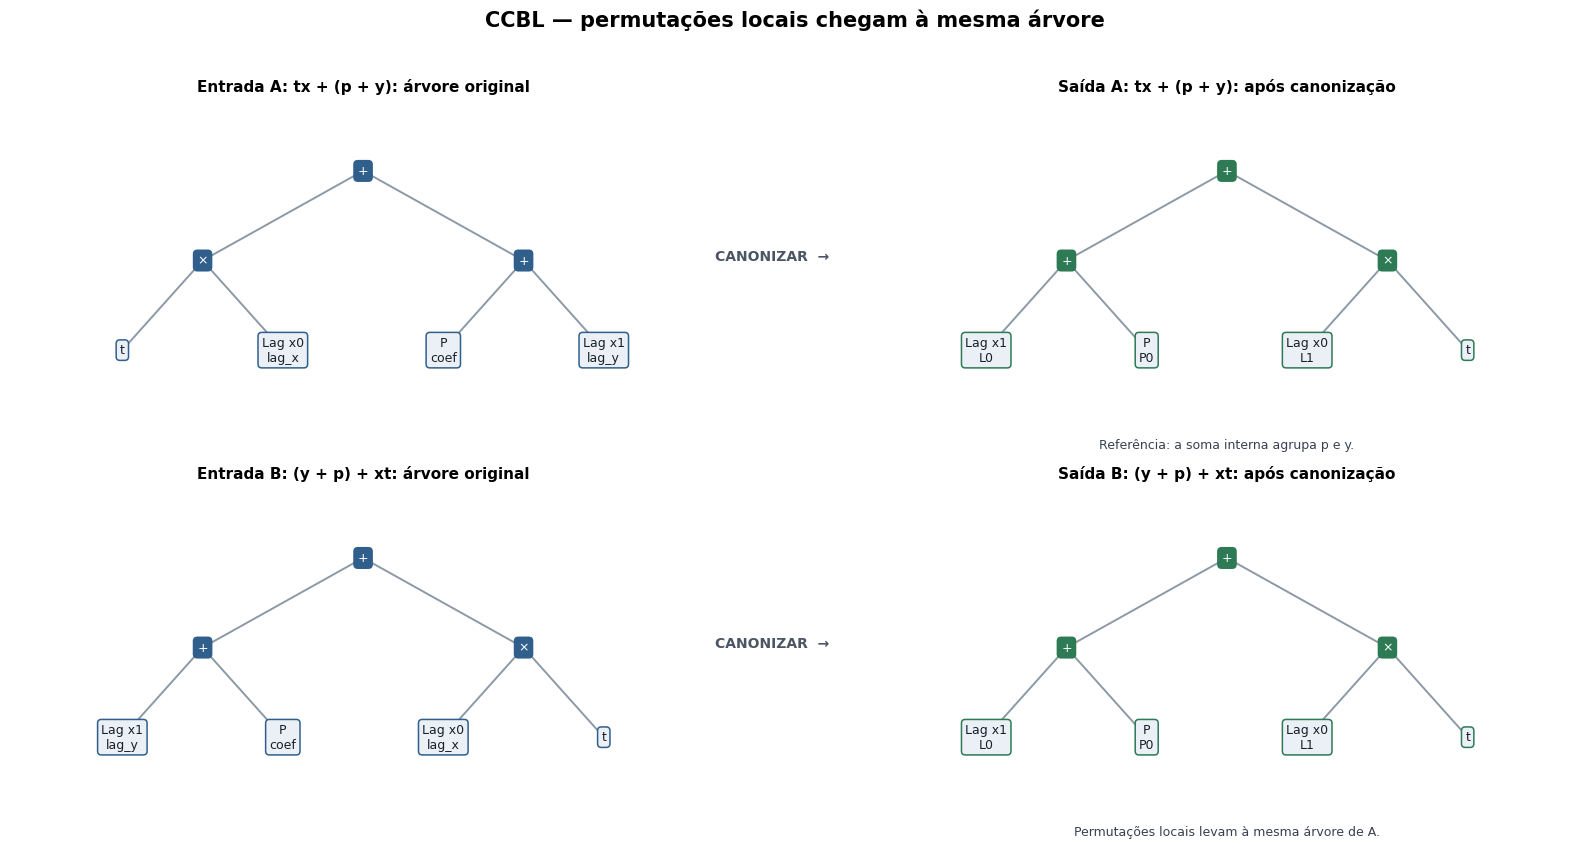

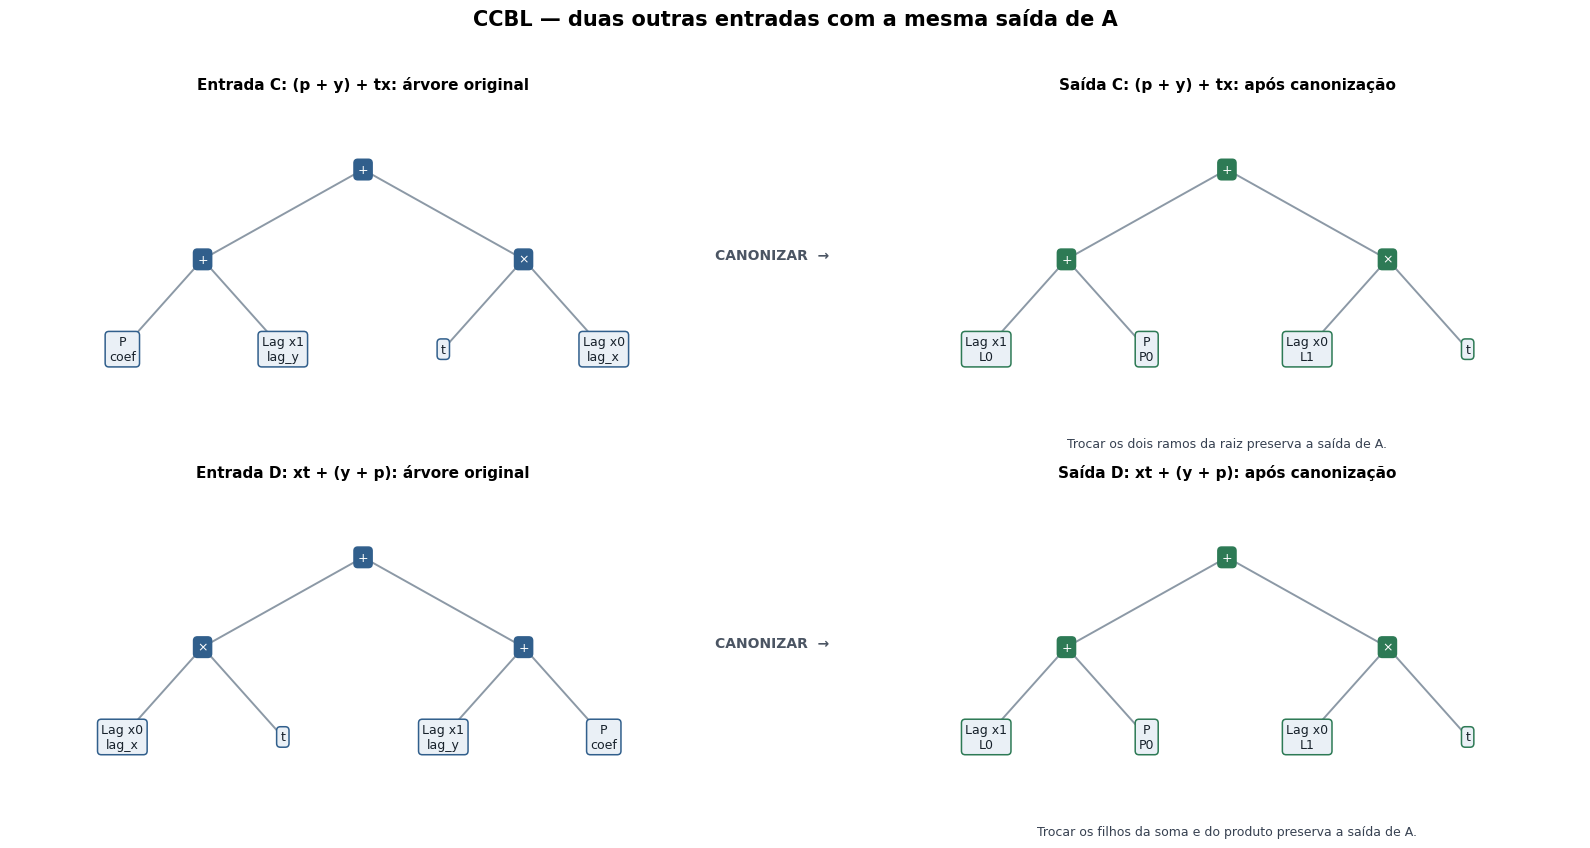

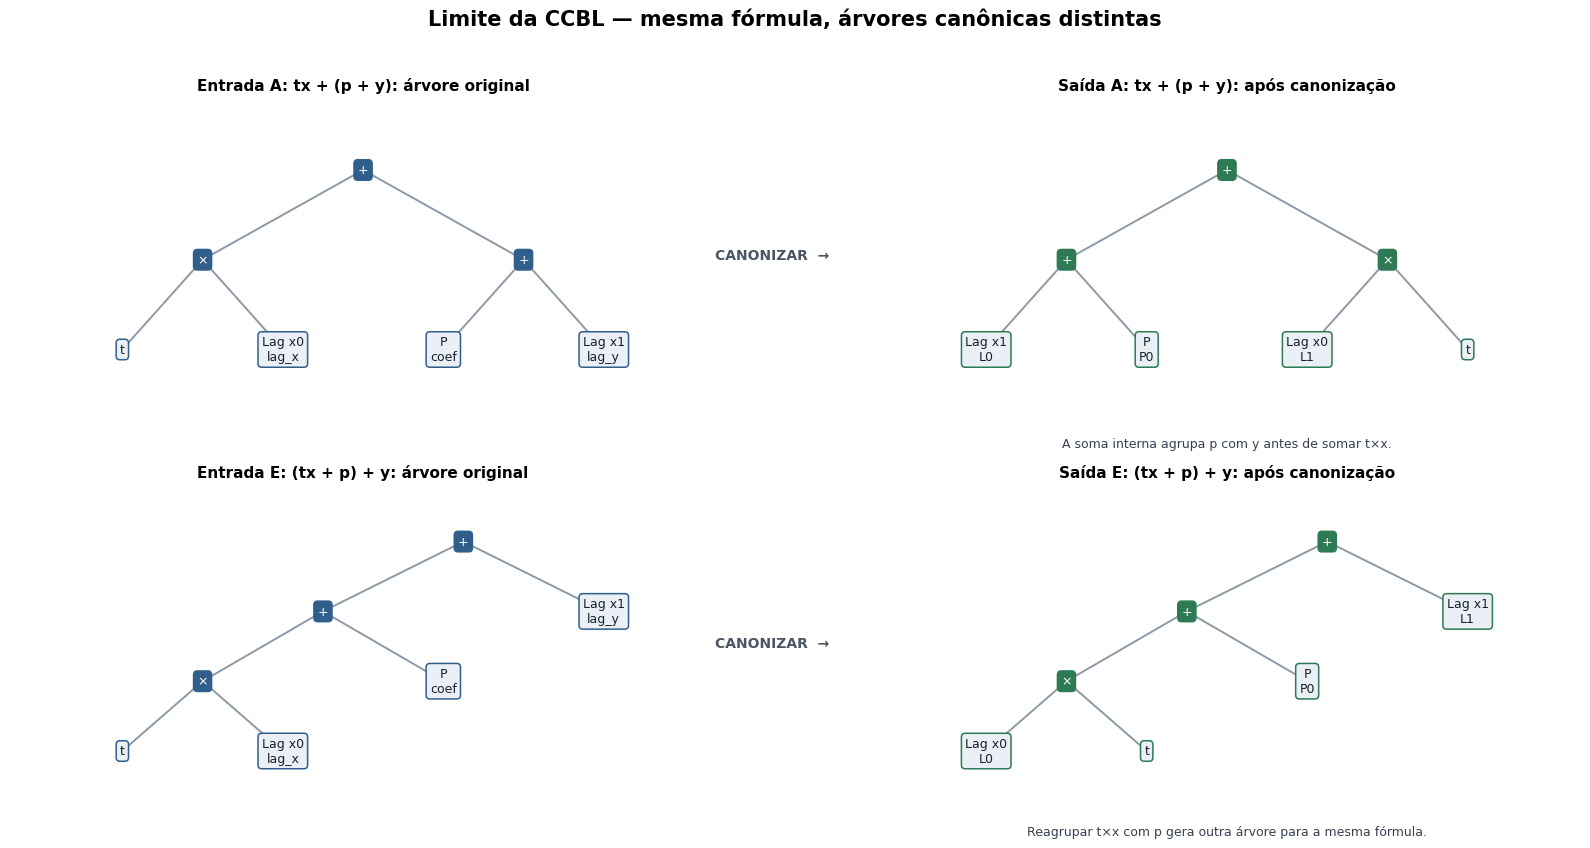

In [4]:
from IPython.display import display

# Todas as variantes mantêm os mesmos slots e representam t*x + p + y.
ccbl_complex_c = Add(Add(p, y), Multiply(t, x))
ccbl_complex_d = Add(Multiply(x, t), Add(y, p))
ccbl_complex_e = Add(Add(Multiply(t, x), p), y)

ccbl_variants = [
    ("A", ccbl_complex_a, "(t × x) + (p + y)"),
    ("B", ccbl_complex_b, "(y + p) + (x × t)"),
    ("C", ccbl_complex_c, "(p + y) + (t × x)"),
    ("D", ccbl_complex_d, "(x × t) + (y + p)"),
    ("E", ccbl_complex_e, "((t × x) + p) + y"),
]
reference_tree = ccbl.canonicalize(ccbl_complex_a)
# A forma polinomial da seção 2 verifica a identidade algébrica das entradas.
reference_polynomial = simplipy.canonical_key(ccbl_complex_a)
ccbl_variant_rows = []
for label, expression, formula in ccbl_variants:
    same_formula = simplipy.canonical_key(expression) == reference_polynomial
    same_tree = ccbl.canonicalize(expression) == reference_tree
    assert same_formula, f"{label}: a fórmula deve continuar igual à de A."
    assert same_tree == (label in {"A", "B", "C", "D"})
    ccbl_variant_rows.append({
        "Caso": label, "Expressão": formula,
        "Mesma fórmula de A": same_formula,
        "Mesma árvore CCBL de A": same_tree,
    })
display(pd.DataFrame(ccbl_variant_rows))

show_transformations(
    [("A: tx + (p + y)", ccbl_complex_a), ("B: (y + p) + xt", ccbl_complex_b)],
    ccbl.canonicalize,
    "CCBL — permutações locais chegam à mesma árvore",
    captions=[
        "Referência: a soma interna agrupa p e y.",
        "Permutações locais levam à mesma árvore de A.",
    ],
)
show_transformations(
    [("C: (p + y) + tx", ccbl_complex_c), ("D: xt + (y + p)", ccbl_complex_d)],
    ccbl.canonicalize,
    "CCBL — duas outras entradas com a mesma saída de A",
    captions=[
        "Trocar os dois ramos da raiz preserva a saída de A.",
        "Trocar os filhos da soma e do produto preserva a saída de A.",
    ],
)
show_transformations(
    [("A: tx + (p + y)", ccbl_complex_a), ("E: (tx + p) + y", ccbl_complex_e)],
    ccbl.canonicalize,
    "Limite da CCBL — mesma fórmula, árvores canônicas distintas",
    captions=[
        "A soma interna agrupa p com y antes de somar t×x.",
        "Reagrupar t×x com p gera outra árvore para a mesma fórmula.",
    ],
)

### Visual — onde deixa de funcionar

Aqui só mudamos a parentização de uma soma. A associatividade diz que as entradas representam a mesma soma, mas as saídas continuam com formatos diferentes porque o método não achata nós `Add`.

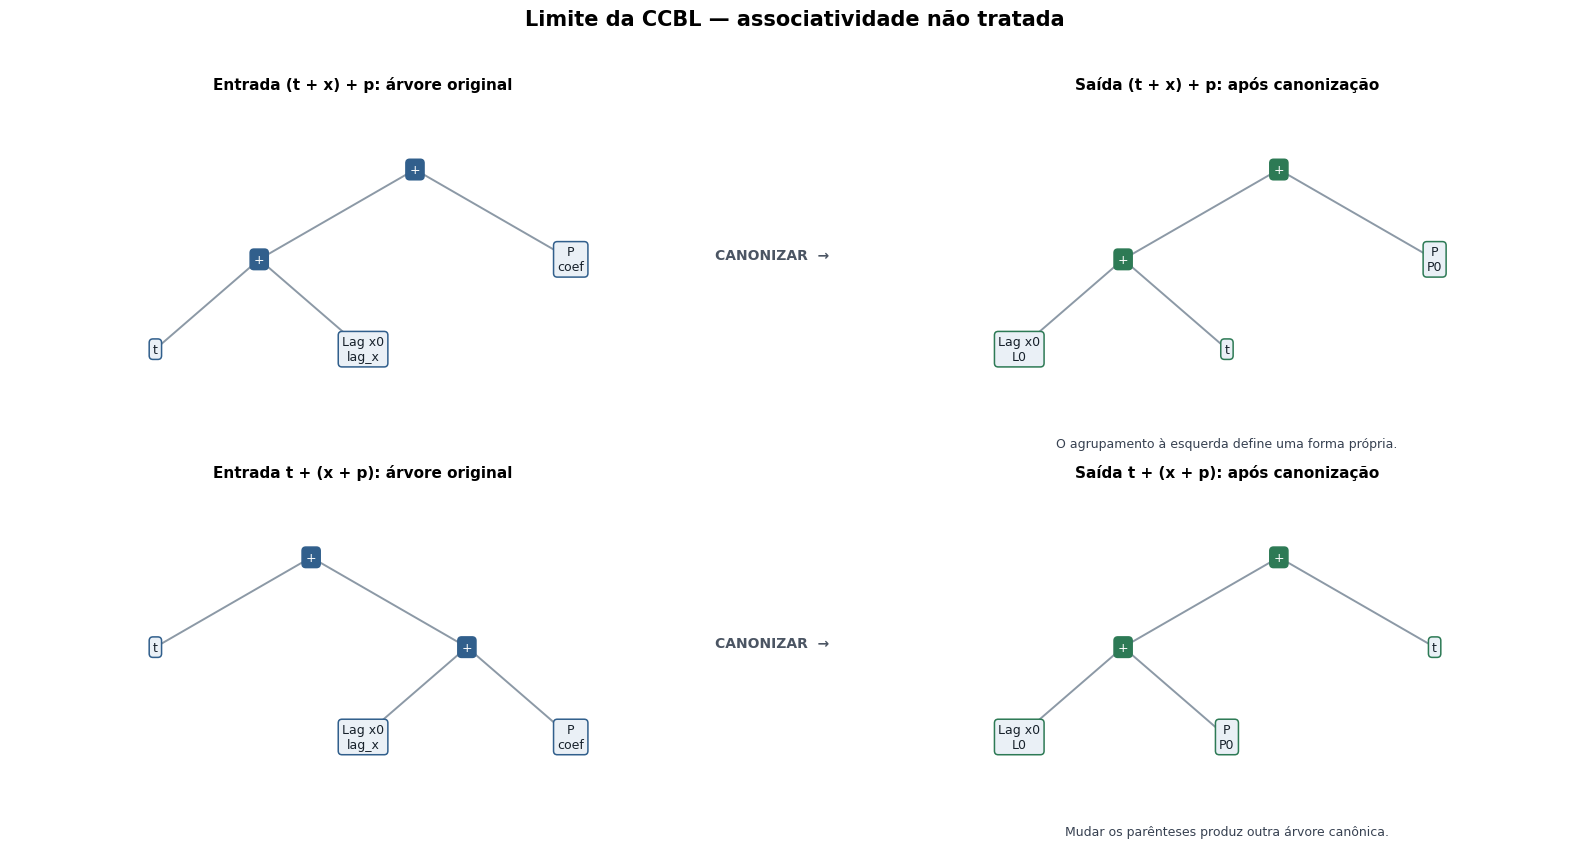

In [5]:
show_transformations(
    [("(t + x) + p", assoc_a), ("t + (x + p)", assoc_b)],
    ccbl.canonicalize,
    "Limite da CCBL — associatividade não tratada",
    captions=[
        "O agrupamento à esquerda define uma forma própria.",
        "Mudar os parênteses produz outra árvore canônica.",
    ],
)

**Limite demonstrado:** a primeira linha é o exemplo complexo coberto pela garantia da CCBL. As duas linhas seguintes mostram que fórmulas iguais por associatividade ou distributividade ainda podem possuir chaves diferentes. Além disso, a chave é do esqueleto: valores numéricos de parâmetros e atrasos não participam dela.

### Produto de três variáveis com um termo adicional — \(x_0x_1x_2+x_0\)

Usamos \(x_j=X_j(t-1)\): três séries distintas, todas no mesmo lag 1. Os índices 0, 1 e 2 identificam as séries. Os slots \(\texttt{lag_0},\texttt{lag_1},\texttt{lag_2}\) guardam esse atraso. O \(x_0\) somado é a mesma variável que aparece no produto.

Comparamos **A** = \(((x_0x_1)x_2)+x_0\), **B** = \((x_2(x_1x_0))+x_0\) e **C** = \((x_0(x_1x_2))+x_0\). B troca os filhos em dois nós do produto de A; C muda seu agrupamento. O termo adicional \(+x_0\) é mantido nas três entradas.

A tabela mostra uma **lista aninhada para leitura**, em que o primeiro elemento é o operador e os seguintes são seus filhos. As figuras preservam os nomes dos slots; na lista abreviamos cada folha por \(x_j\).

,Fórmula,Lista da saída,Mesma árvore de A?
Entrada,,,
A,((x_0 × x_1) × x_2) + x_0,"['ADD', 'x_0', ['MUL', 'x_2', ['MUL', 'x_0', 'x_1']]]",True
B,(x_2 × (x_1 × x_0)) + x_0,"['ADD', 'x_0', ['MUL', 'x_2', ['MUL', 'x_0', 'x_1']]]",True
C,(x_0 × (x_1 × x_2)) + x_0,"['ADD', 'x_0', ['MUL', 'x_0', ['MUL', 'x_1', 'x_2']]]",False


3 entradas algebricamente equivalentes → 2 árvores CCBL.


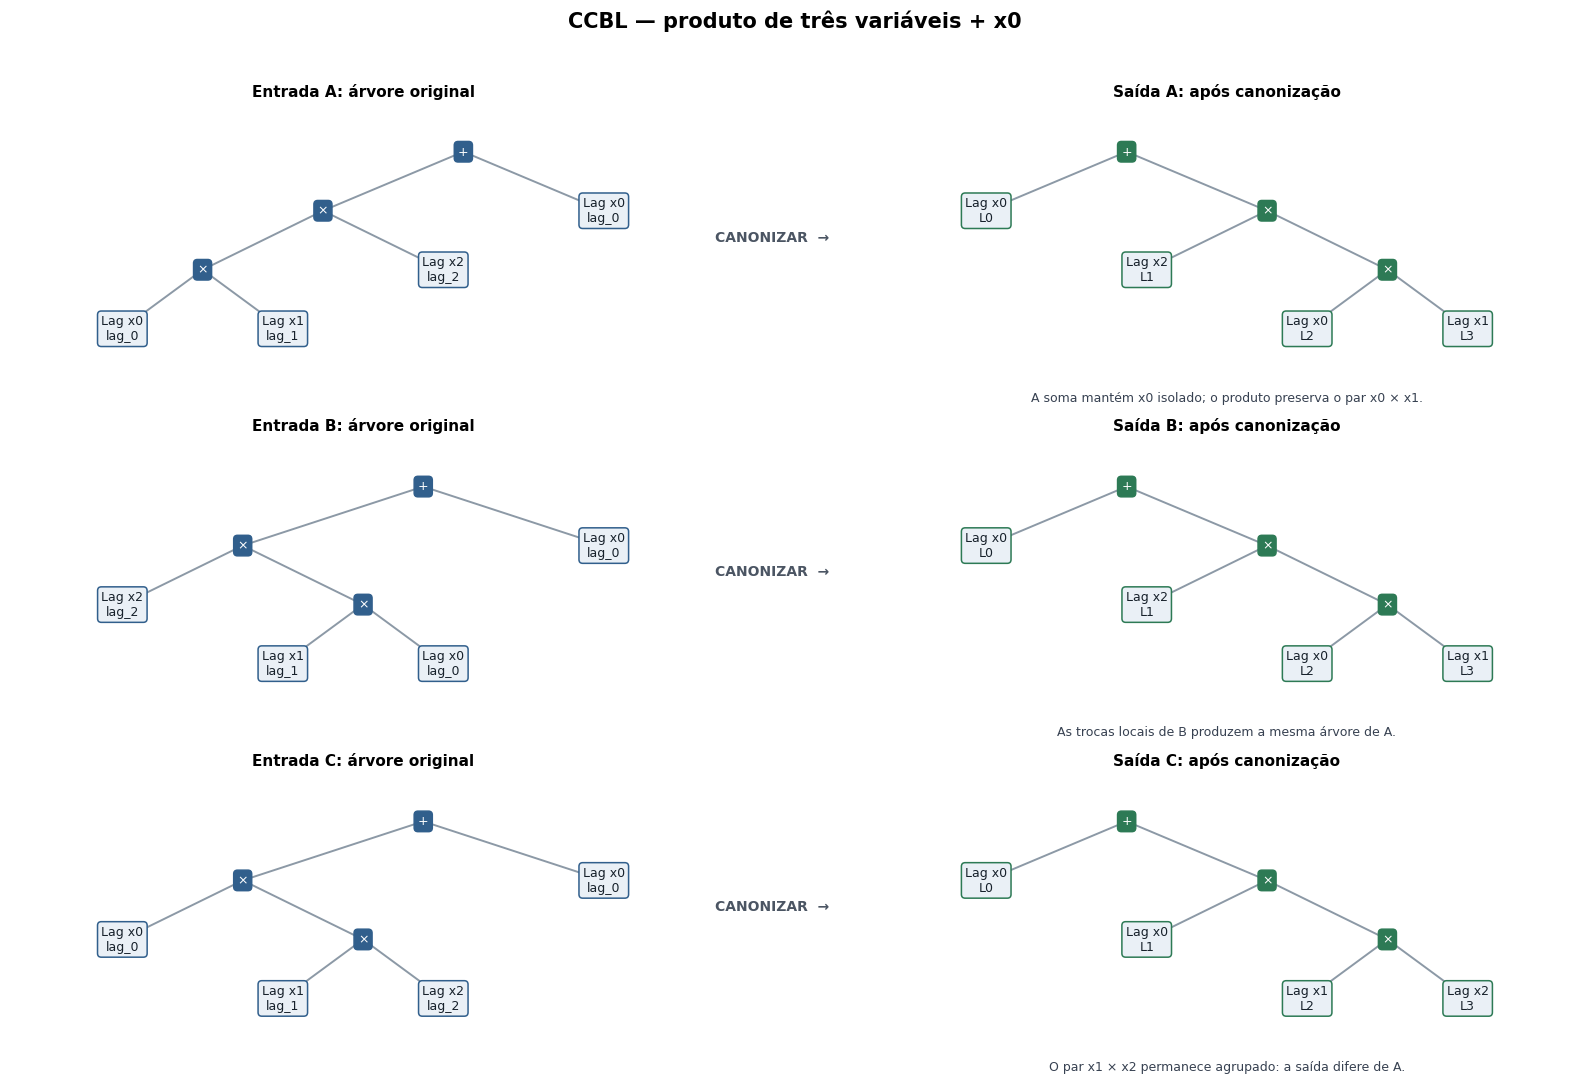

In [17]:
from IPython.display import display

# Cada símbolo representa uma série diferente; todos os atrasos valem 1.
triple_x0, triple_x1, triple_x2 = (
    Lag(0, "lag_0"), Lag(1, "lag_1"), Lag(2, "lag_2")
)
triple_lag_values = {"lag_0": 1, "lag_1": 1, "lag_2": 1}
triple_variants = {
    "A": Add(Multiply(Multiply(triple_x0, triple_x1), triple_x2), triple_x0),
    "B": Add(Multiply(triple_x2, Multiply(triple_x1, triple_x0)), triple_x0),
    "C": Add(Multiply(triple_x0, Multiply(triple_x1, triple_x2)), triple_x0),
}
triple_formulas = {
    "A": "((x_0 × x_1) × x_2) + x_0",
    "B": "(x_2 × (x_1 × x_0)) + x_0",
    "C": "(x_0 × (x_1 × x_2)) + x_0",
}


def triple_list_for_display(tree):
    """Abrevia somente as árvores deste exemplo para visualizar a estrutura."""
    if isinstance(tree, Lag):
        return f"x_{tree.variable}"
    if isinstance(tree, (Add, Multiply)):
        operator = "ADD" if isinstance(tree, Add) else "MUL"
        return [operator, triple_list_for_display(tree.left),
                triple_list_for_display(tree.right)]
    label, children = tree  # Formato n-ário retornado pelas outras duas técnicas.
    if not children:
        leaf_names = {f"LAG x{j}\nlag_{j}": f"x_{j}" for j in range(3)}
        return leaf_names[label]
    return [label, *(triple_list_for_display(child) for child in children)]


# A forma polinomial confirma a igualdade das três fórmulas, incluindo + x_0.
assert len({simplipy.canonical_key(tree) for tree in triple_variants.values()}) == 1
triple_ccbl_keys = {
    label: ccbl.canonical_key(tree) for label, tree in triple_variants.items()
}
triple_ccbl_lists = {
    label: triple_list_for_display(ccbl.canonicalize(tree))
    for label, tree in triple_variants.items()
}
assert triple_ccbl_keys["A"] == triple_ccbl_keys["B"]
assert triple_ccbl_keys["A"] != triple_ccbl_keys["C"]
assert triple_ccbl_lists["A"] == [
    "ADD", "x_0", ["MUL", "x_2", ["MUL", "x_0", "x_1"]]
]
assert triple_ccbl_lists["C"] == [
    "ADD", "x_0", ["MUL", "x_0", ["MUL", "x_1", "x_2"]]
]

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame([
        {"Entrada": label, "Fórmula": triple_formulas[label],
         "Lista da saída": repr(triple_ccbl_lists[label]),
         "Mesma árvore de A?": triple_ccbl_keys[label] == triple_ccbl_keys["A"]}
        for label in triple_variants
    ]).set_index("Entrada"))
print("3 entradas algebricamente equivalentes →",
      len(set(triple_ccbl_keys.values())), "árvores CCBL.")

show_transformations(
    list(triple_variants.items()), ccbl.canonicalize,
    "CCBL — produto de três variáveis + x0",
    captions=[
        "A soma mantém x0 isolado; o produto preserva o par x0 × x1.",
        "As trocas locais de B produzem a mesma árvore de A.",
        "O par x1 × x2 permanece agrupado: a saída difere de A.",
    ],
    figsize=(16, 11),
)

**O que a célula fez.** Criou três escritas de \(x_0x_1x_2+x_0\), canonizou cada uma e verificou as igualdades com assert. A e B chegam à mesma árvore; C conserva outro agrupamento do produto. Na raiz ADD, o \(x_0\) isolado fica antes do produto porque LAG vem antes de MULTIPLY. Dentro do produto de A, \(x_2\) fica antes do par \((x_0,x_1)\) pelo mesmo critério. Assim, a ordenação acontece **dentro de cada nó**, preservando dois níveis de multiplicação abaixo da soma. Os slots L0 a L3 são renomeados por ocorrência e todos representam atraso 1; as duas folhas da série 0 continuam correspondendo ao mesmo \(X_0(t-1)\).

## 2. Normalização restrita inspirada em SimpliPy/Flash-ANSR

> **Legenda:** evidencia a unificação AC-distributiva e o limite causado pela expansão exponencial.

O núcleo oficial do SimpliPy usa construtores associativo-comutativos, aritmética exata e regras de reescrita orientadas por redução de complexidade. Para o vocabulário menor deste projeto, a implementação local produz uma forma normal polinomial de semianel:

- achata e ordena somas e produtos;
- distribui produtos sobre somas;
- ordena fatores e monômios;
- normaliza recursivamente o argumento de `Tanh`, tratando a chamada resultante como um átomo opaco;
- interrompe a expansão acima de `max_terms=4096`.

Dentro desse fragmento e abaixo do limite, a chave é única módulo associatividade, comutatividade e distributividade. Os nomes dos slots são preservados porque eles selecionam valores distintos em `MechanismBinding`.

### Passo a passo, em linguagem simples

Pense na fórmula como uma caixa de peças de montar. Queremos organizar essas peças sempre do mesmo jeito, para reconhecer duas escritas da mesma conta. Os passos abaixo descrevem a adaptação local deste notebook.

1. **Lemos a árvore de baixo para cima.** Um lag, um parâmetro ou o tempo vira uma peça identificada pelo seu tipo e pelo seu nome. Por exemplo, `LAG(0, "a")` identifica a série 0 e o slot chamado `a`. O nome do slot continua guardado, pois ele indica qual valor será usado depois.

2. **Transformamos a expressão em uma soma de produtos.** Ao encontrar uma soma, juntamos suas parcelas. Ao encontrar um produto de somas, multiplicamos cada parcela de um lado por cada parcela do outro. Por exemplo, `(t + u) × (v + w)` vira `t×v + t×w + u×v + u×w`. Assim, os agrupamentos originais dão lugar a uma lista de parcelas.

3. **Ordenamos as peças dentro de cada produto.** O código compara primeiro o nome do tipo, em ordem de texto: `LAG → PARAMETER → TANH → TIME`. Entre lags, compara primeiro o índice da série e depois o nome do slot; entre parâmetros, compara o nome do slot. Por isso, um lag fica antes de `t`, e o produto `t×v` passa a ser escrito `v×t`. Os valores numéricos dos coeficientes e dos atrasos ficam no binding e entram em uma etapa posterior.

4. **Ordenamos a lista de produtos.** Comparamos a primeira peça de cada produto. Se houver empate, olhamos a segunda, depois a terceira, e assim por diante. Quando um produto é o início exato de outro, o mais curto vem primeiro. É parecido com ordenar palavras em um dicionário. Parcelas repetidas continuam representadas com sua quantidade de ocorrências.

5. **Montamos a saída organizada.** Um nó `ADD` reúne as parcelas; cada nó `MUL` reúne os fatores de uma parcela. Para `tanh(...)`, organizamos primeiro o interior e guardamos a chamada inteira como uma peça. Durante a expansão, o limite de 4.096 parcelas controla o tamanho que pode ser materializado.

**Exemplo da figura.** Abreviando os lags com slots `a`, `b` e `c` por `u`, `v` e `w`:

```text
Entrada:                     (t + u) × (v + w)
Após distribuir:             t×v + t×w + u×v + u×w
Após ordenar fatores/termos: u×v + u×w + v×t + w×t
```

`u×v` vem antes de `u×w` porque o primeiro fator empata e o slot `b` vem antes de `c`. Ambos ficam antes das parcelas que começam por `v` ou `w`. Essa ordem é uma convenção de escrita reproduzível; a importância das variáveis é uma questão separada.

**Onde conferir:** [canonicalizer.py](simplipy_flash_ansr/canonicalizer.py), nas funções `_polynomial`, `_render` e na comparação dos objetos `Atom`.

In [6]:
a = Time()
b = Lag(0, "a")
c = Lag(0, "b")
d = Lag(0, "c")

factored = Multiply(Add(a, b), Add(c, d))
expanded_shuffled = Add(
    Multiply(b, d),
    Add(Multiply(a, c), Add(Multiply(d, a), Multiply(c, b))),
)

simplipy_complex_table = pd.DataFrame([
    {
        "entrada": "fatorada",
        "fórmula": to_skeleton_formula(factored),
        "forma canônica": simplipy.canonical_key(factored),
    },
    {
        "entrada": "expandida, permutada e parentizada de outro modo",
        "fórmula": to_skeleton_formula(expanded_shuffled),
        "forma canônica": simplipy.canonical_key(expanded_shuffled),
    },
])

assert simplipy.canonical_key(factored) == simplipy.canonical_key(expanded_shuffled)
simplipy_complex_table

,entrada,fórmula,forma canônica
0,fatorada,"((t + LAG(0, a)) * (LAG(0, b) + LAG(0, c)))","ADD(MUL(LAG[0,a],LAG[0,b]),MUL(LAG[0,a],LAG[0,..."
1,"expandida, permutada e parentizada de outro modo","((LAG(0, a) * LAG(0, c)) + ((t * LAG(0, b)) + ...","ADD(MUL(LAG[0,a],LAG[0,b]),MUL(LAG[0,a],LAG[0,..."


### Visual — caso mais avançado tratado

Uma entrada está fatorada e a outra possui quatro produtos expandidos, permutados e parentizados de outra maneira. A forma normal distribui, achata e ordena tudo; por isso, as duas saídas são a mesma árvore n-ária `ADD → MUL → átomos`.

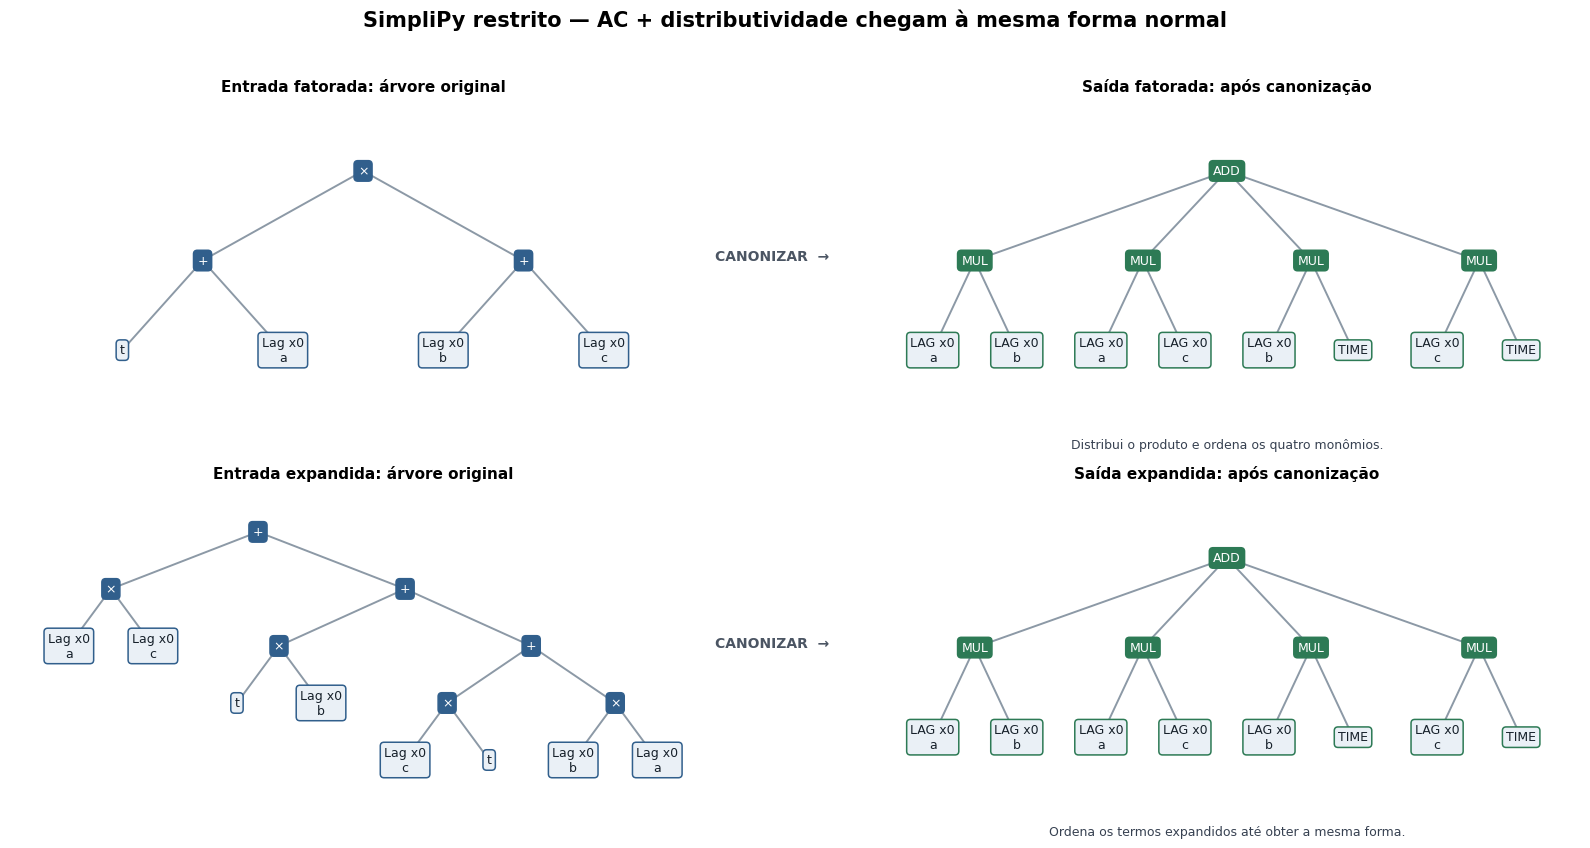

In [7]:
show_transformations(
    [("fatorada", factored), ("expandida", expanded_shuffled)],
    lambda expression: simplipy.canonical_structure(expression, max_terms=4096),
    "SimpliPy restrito — AC + distributividade chegam à mesma forma normal",
    captions=[
        "Distribui o produto e ordena os quatro monômios.",
        "Ordena os termos expandidos até obter a mesma forma.",
    ],
)

In [8]:
def product_of_sums(pair_count: int):
    factors = [Add(Lag(0, f"L{2*i}"), Lag(0, f"L{2*i+1}")) for i in range(pair_count)]
    return reduce(Multiply, factors)


limit_rows = []
for pair_count in (8, 10, 12, 13):
    expression = product_of_sums(pair_count)
    try:
        key = simplipy.canonical_key(expression, max_terms=4096)
        status = "normalizada"
        canonical_terms = key.count("MUL(")
    except simplipy.ExpansionLimitError as error:
        status = str(error)
        canonical_terms = np.nan
    limit_rows.append({
        "fatores (somas binárias)": pair_count,
        "nós da AST": node_count(expression),
        "termos matematicamente esperados": 2**pair_count,
        "termos materializados": canonical_terms,
        "resultado": status,
    })

pd.DataFrame(limit_rows)

,fatores (somas binárias),nós da AST,termos matematicamente esperados,termos materializados,resultado
0,8,31,256,256.0,normalizada
1,10,39,1024,1024.0,normalizada
2,12,47,4096,4096.0,normalizada
3,13,51,8192,NaN,normal form would exceed 4096 additive terms


### Visual — momento em que deixa de funcionar

Com 13 somas binárias multiplicadas, a entrada ainda tem somente 51 nós, mas a forma distributiva exigiria 8.192 monômios. O método interrompe deliberadamente em 4.096 termos. O painel vermelho é parte do resultado: não existe árvore canônica materializada sob essa configuração.

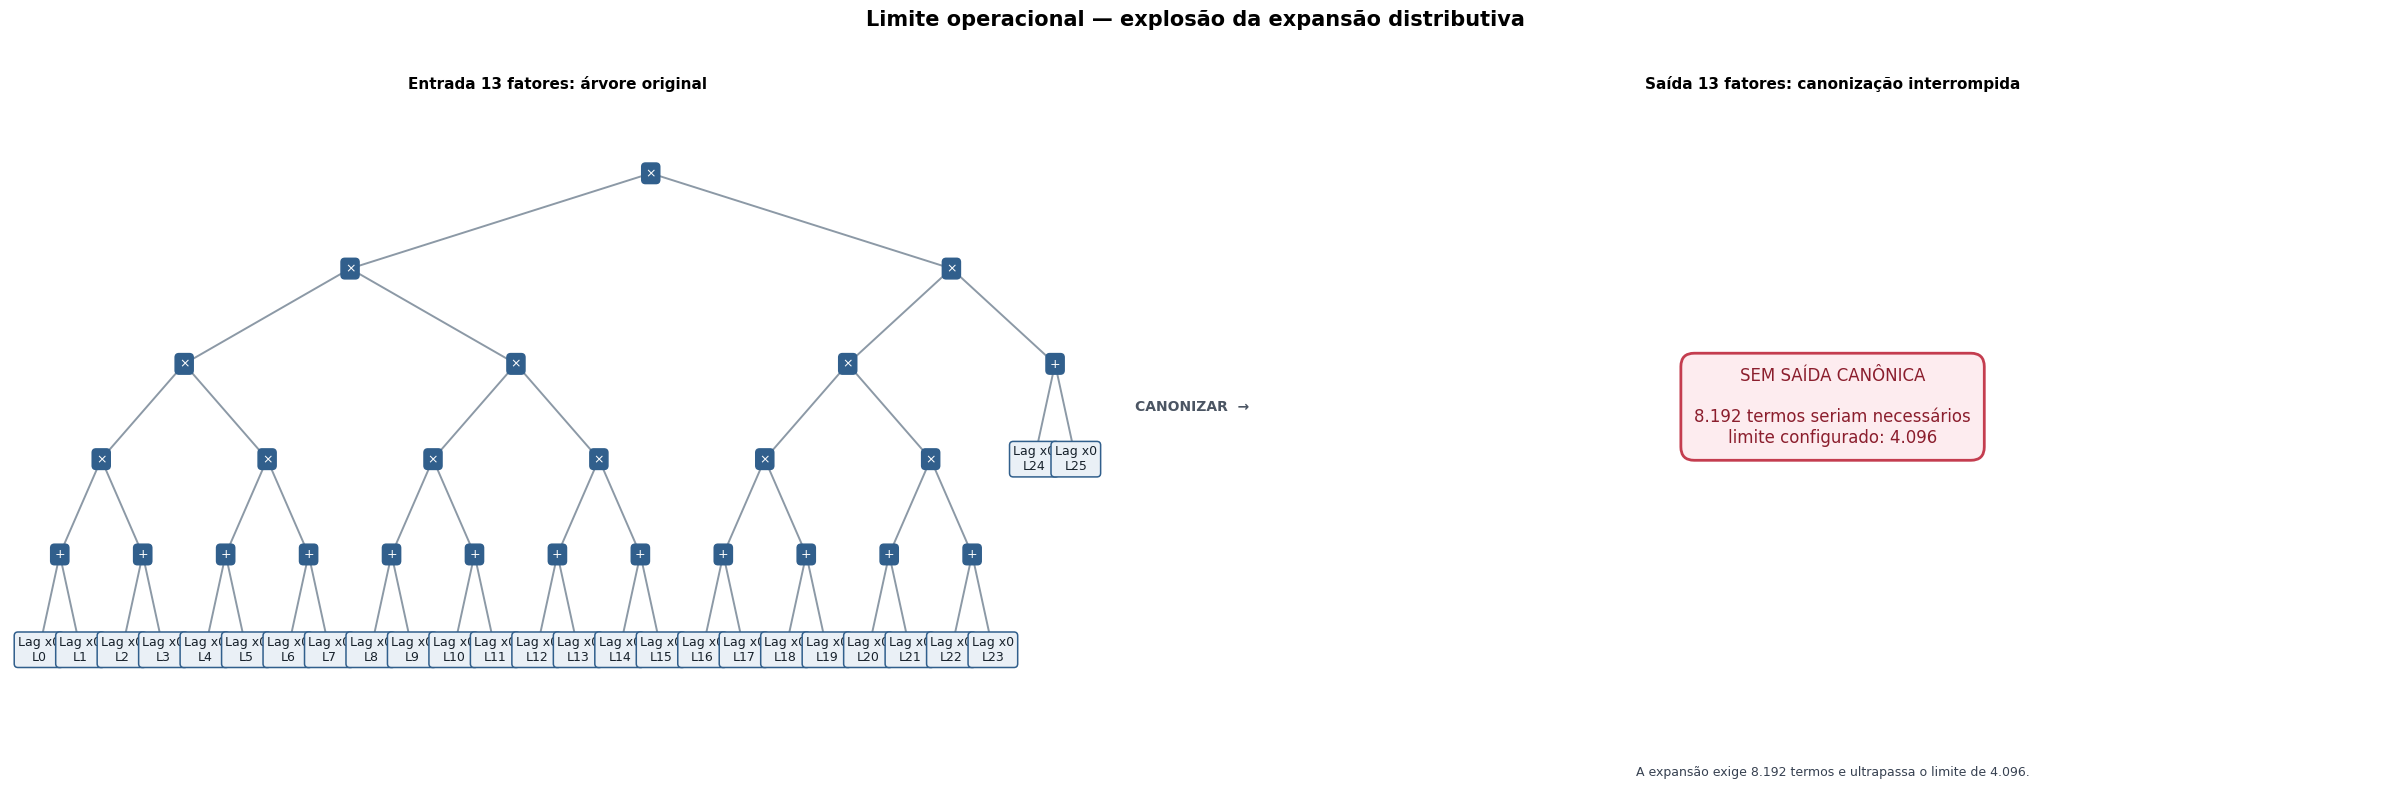

In [9]:
def balanced_product_of_sums(pair_count):
    level = [Add(Lag(0, f"L{2*i}"), Lag(0, f"L{2*i+1}")) for i in range(pair_count)]
    while len(level) > 1:
        next_level = []
        for index in range(0, len(level), 2):
            next_level.append(Multiply(level[index], level[index + 1]) if index + 1 < len(level) else level[index])
        level = next_level
    return level[0]


expansion_failure = balanced_product_of_sums(13)
show_transformations(
    [("13 fatores", expansion_failure)],
    lambda expression: simplipy.canonical_structure(expression, max_terms=4096),
    "Limite operacional — explosão da expansão distributiva",
    failure_message="SEM SAÍDA CANÔNICA\n\n8.192 termos seriam necessários\nlimite configurado: 4.096",
    figsize=(24, 8),
    captions=[
        "A expansão exige 8.192 termos e ultrapassa o limite de 4.096.",
    ],
)

**Limites:** a garantia vale somente para o fragmento tratado como polinômio sobre átomos nomeados. `Tanh` não é expandida por identidades analíticas; parâmetros e atrasos ligados a valores numéricos não são comparados; renomear um slot muda a chave; e a expansão distributiva cresce exponencialmente. O limite evita que uma árvore pequena materialize milhões de termos.

### Produto de três variáveis com \(+x_0\) — duas parcelas na soma de produtos

Reutilizamos as entradas A, B e C da seção 1. A normalização reúne os três fatores do produto e mantém \(x_0\) como outra parcela. A lista de produtos abreviada fica \(\big[[x_0],[x_0,x_1,x_2]\big]\): a lista externa reúne as duas parcelas; cada lista interna reúne os fatores daquela parcela. O termo \(x_0\) vem primeiro porque sua lista de fatores é um prefixo mais curto da lista do produto triplo.

,Fórmula,Lista da saída,Mesma árvore de A?
Entrada,,,
A,((x_0 × x_1) × x_2) + x_0,"['ADD', ['MUL', 'x_0'], ['MUL', 'x_0', 'x_1', 'x_2']]",True
B,(x_2 × (x_1 × x_0)) + x_0,"['ADD', ['MUL', 'x_0'], ['MUL', 'x_0', 'x_1', 'x_2']]",True
C,(x_0 × (x_1 × x_2)) + x_0,"['ADD', ['MUL', 'x_0'], ['MUL', 'x_0', 'x_1', 'x_2']]",True


3 entradas → 1 forma normal.
Lista de produtos abreviada: [['x_0'], ['x_0', 'x_1', 'x_2']]


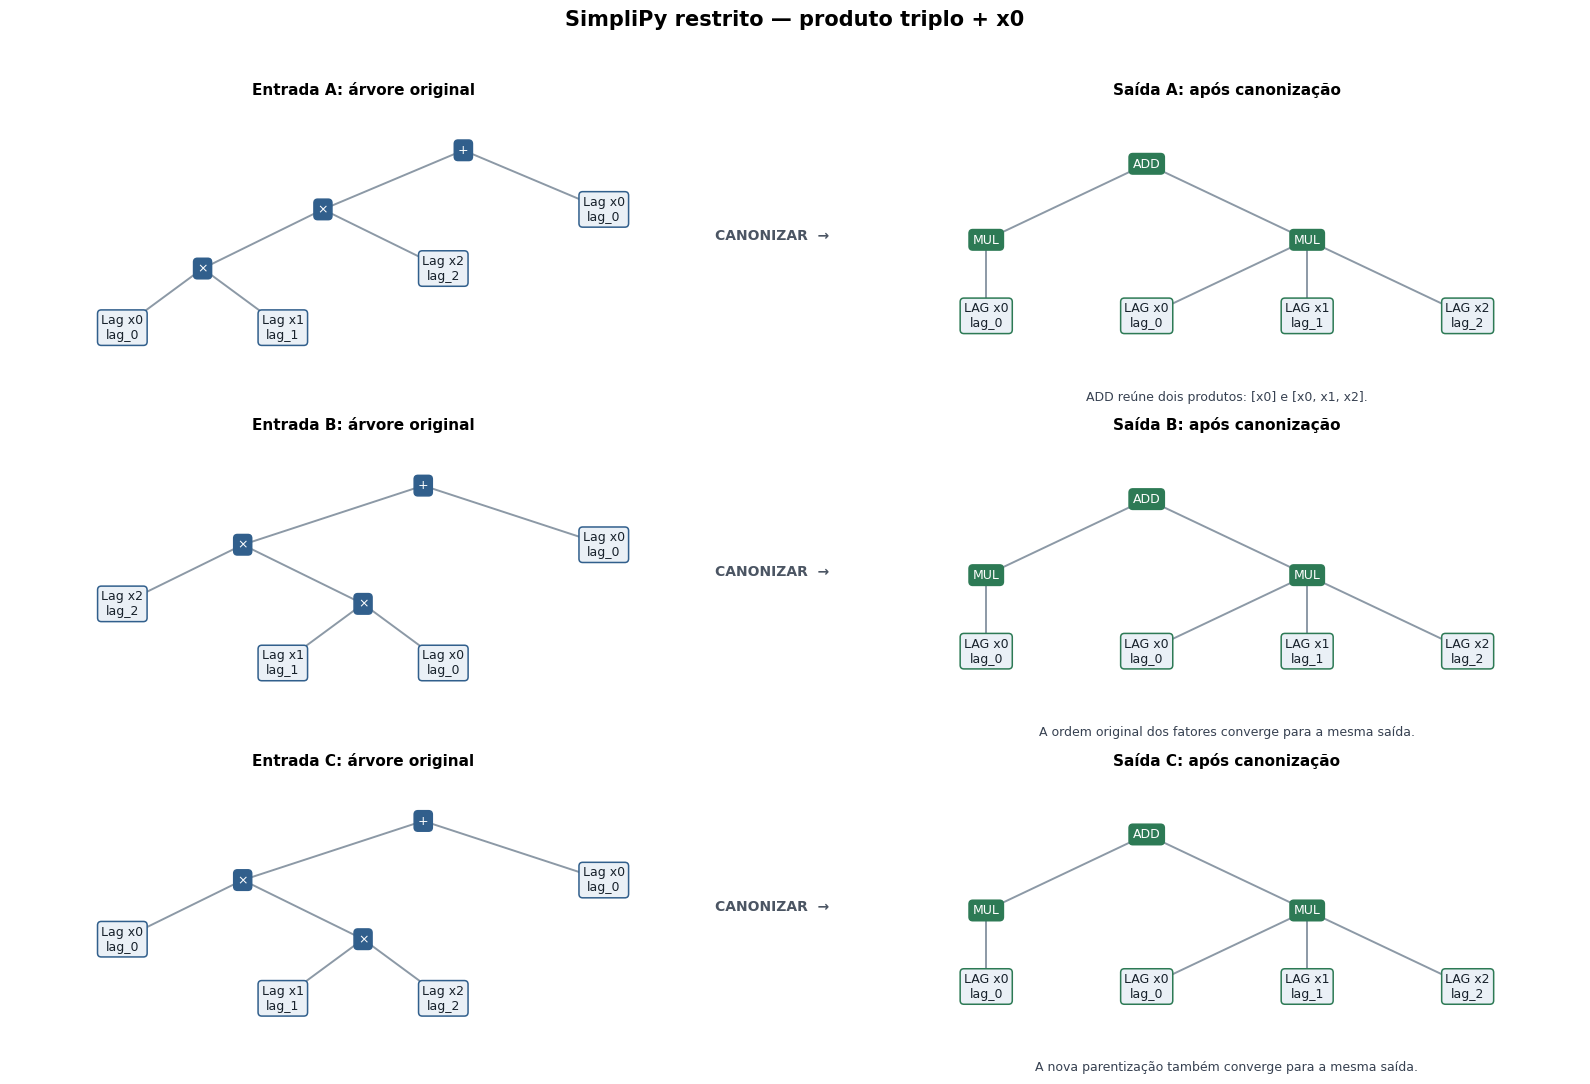

In [18]:
triple_simplipy_keys = {
    label: simplipy.canonical_key(tree) for label, tree in triple_variants.items()
}
triple_simplipy_lists = {
    label: triple_list_for_display(simplipy.canonical_structure(tree))
    for label, tree in triple_variants.items()
}
triple_simplipy_expected = [
    "ADD", ["MUL", "x_0"], ["MUL", "x_0", "x_1", "x_2"]
]
assert len(set(triple_simplipy_keys.values())) == 1
assert all(value == triple_simplipy_expected
           for value in triple_simplipy_lists.values())

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame([
        {"Entrada": label, "Fórmula": triple_formulas[label],
         "Lista da saída": repr(triple_simplipy_lists[label]),
         "Mesma árvore de A?": triple_simplipy_keys[label] == triple_simplipy_keys["A"]}
        for label in triple_variants
    ]).set_index("Entrada"))
print("3 entradas → 1 forma normal.")
print("Lista de produtos abreviada:",
      [term[1:] for term in triple_simplipy_lists["A"][1:]])

show_transformations(
    list(triple_variants.items()), simplipy.canonical_structure,
    "SimpliPy restrito — produto triplo + x0",
    captions=[
        "ADD reúne dois produtos: [x0] e [x0, x1, x2].",
        "A ordem original dos fatores converge para a mesma saída.",
        "A nova parentização também converge para a mesma saída.",
    ],
    figsize=(16, 11),
)

**O que a célula fez.** Normalizou as três entradas e confirmou uma única saída. ADD contém duas parcelas: MUL com apenas \(x_0\), representando o termo isolado, e MUL com os três fatores \(x_0,x_1,x_2\). A forma normal usa **soma → produtos**, incluindo um produto de um único fator para manter o mesmo formato em todas as parcelas. Essa leitura vale para a forma polinomial sobre átomos; fatores com funções como tanh(...) também guardam a estrutura de seus argumentos.

## 3. Canonização e deduplicação inspiradas em Verifier-Guided Discovery

> **Legenda:** evidencia a união por comportamento observado e o risco de falsos equivalentes numéricos.

A primeira fase cria uma chave estrutural única sob associatividade e comutatividade, sem distribuir. A segunda executa cada representante estrutural em várias condições iniciais e agrupa assinaturas de rollout arredondadas. Isso pode encontrar equivalências que a chave não encontra, mas é evidência no domínio testado — não uma prova global.

### Passo a passo, em linguagem simples

Aqui organizamos as fórmulas e depois observamos o que elas produzem quando executadas. Existem duas decisões diferentes: **a posição dos ramos na árvore** e **qual fórmula fica como representante de um grupo**. Estes passos descrevem a adaptação local do notebook.

1. **Juntamos operações iguais que estão encadeadas.** Por exemplo, `a + (b + c)` vira uma soma com três filhos: `[a, b, c]`. Fazemos o mesmo com multiplicações encadeadas. Um produto que contém uma soma mantém essa soma dentro dele; por isso, a forma fatorada e a expandida podem continuar com árvores diferentes.

2. **Damos uma etiqueta de texto a cada ramo.** Exemplos: `TIME`, `PARAMETER[p]`, `LAG[0,l1]` ou `MUL(LAG[0,l1],TIME)`. A etiqueta inclui a estrutura dos filhos, a série e os nomes dos slots.

3. **Ordenamos os filhos pela etiqueta completa.** A comparação é caractere por caractere, como em um dicionário. Pelos nomes usados no código, os tipos seguem `ADD → LAG → MUL → PARAMETER → TANH → TIME`, quando aparecem entre os filhos a ordenar. Em caso de empate no tipo, o restante da etiqueta desempata. Como são textos, um rótulo `L10` vem antes de `L2`. Aqui, a ordem depende da escrita dos identificadores.

```text
Entrada:           t + (p + x)
Filhos reunidos:   [TIME, PARAMETER[p], LAG[0,l1]]
Filhos ordenados:  [LAG[0,l1], PARAMETER[p], TIME]
```

4. **Agrupamos as fórmulas que receberam a mesma chave simbólica.** Percorremos a lista de candidatos na ordem recebida. O primeiro candidato de cada grupo fica como representante; os demais ficam registrados como membros desse grupo. A escolha segue a ordem de entrada, enquanto tamanho da fórmula e qualidade de previsão seriam outros possíveis critérios.

5. **Executamos cada representante.** Aplicamos os valores dos parâmetros e dos lags e geramos pequenos trechos da série a partir das condições iniciais escolhidas. No exemplo principal, usamos três históricos iniciais e 12 passos por histórico. A lista dos valores produzidos funciona como uma “impressão digital” do comportamento.

6. **Comparamos essas impressões digitais.** Arredondamos os valores para 10 casas decimais no exemplo principal. Representantes com a mesma lista arredondada entram no mesmo grupo comportamental. Novamente, fica o primeiro recebido: como `fatorada` aparece antes de `expandida`, ela é mantida na figura. Inverter a ordem dessas duas candidatas pode trocar o representante escolhido. Candidatos cujo rollout falha ficam separados por sua chave simbólica e marcados como sem verificação.

7. **Interpretamos o resultado dentro das condições testadas.** O grupo indica comportamento coincidente nos históricos, passos e arredondamento usados. O exemplo com a perturbação `1e-12` mostra que oito casas decimais podem esconder uma diferença real entre mecanismos.

**Cuidado com os valores dos slots:** o primeiro agrupamento usa estrutura e nomes, enquanto os valores numéricos são consultados nos rollouts. Para que esse primeiro agrupamento preserve os mecanismos, os candidatos com a mesma chave precisam usar bindings compatíveis. Valores diferentes para os mesmos slots podem ser agrupados antes da simulação nesta implementação.

**Onde conferir:** [canonicalizer.py](verifier_guided/canonicalizer.py), nas funções `canonical_key`, `canonical_structure`, `rollout_signature` e `deduplicate_candidates`.

In [10]:
l1, l2, l3 = Lag(0, "l1"), Lag(0, "l2"), Lag(0, "l3")
vg_factored = Multiply(Add(l1, l2), Add(l2, l3))
vg_expanded = Add(
    Multiply(l2, l3),
    Add(Multiply(l1, l2), Add(Multiply(l2, l2), Multiply(l1, l3))),
)
vg_different = Add(vg_factored, l1)

lag_binding = {"l1": 1, "l2": 2, "l3": 3}
candidates = [
    verifier.Candidate("fatorada", vg_factored, {}, lag_binding),
    verifier.Candidate("expandida", vg_expanded, {}, lag_binding),
    verifier.Candidate("diferente", vg_different, {}, lag_binding),
]
vg_result = verifier.deduplicate_candidates(
    candidates,
    initial_conditions=((0.05, 0.10, 0.15), (-0.10, 0.03, 0.08), (0.20, -0.05, 0.04)),
    steps=12,
    decimals=10,
)

vg_summary = pd.DataFrame([
    {"fase": "candidatos de entrada", "quantidade": len(candidates), "grupos": tuple(c.label for c in candidates)},
    {"fase": "após chave simbólica AC", "quantidade": len(vg_result.symbolic_representatives), "grupos": tuple(vg_result.symbolic_groups.values())},
    {"fase": "após assinatura de rollout", "quantidade": len(vg_result.behavioral_representatives), "grupos": tuple(vg_result.behavioral_groups.values())},
])

assert verifier.canonical_key(vg_factored) != verifier.canonical_key(vg_expanded)
assert len(vg_result.symbolic_representatives) == 3
assert len(vg_result.behavioral_representatives) == 2
vg_summary

,fase,quantidade,grupos
0,candidatos de entrada,3,"(fatorada, expandida, diferente)"
1,após chave simbólica AC,3,"((fatorada,), (expandida,), (diferente,))"
2,após assinatura de rollout,2,"((fatorada, expandida), (diferente,))"


### Visual — caso mais avançado do fluxo Verifier-Guided

A canonização AC ainda produz árvores diferentes para as formas fatorada e expandida. Entretanto, os múltiplos rollouts geram a mesma assinatura e a etapa comportamental coloca ambas no grupo `(fatorada, expandida)`, mantendo apenas um representante. A figura torna explícita a diferença entre **árvore canônica estrutural** e **deduplicação comportamental**.

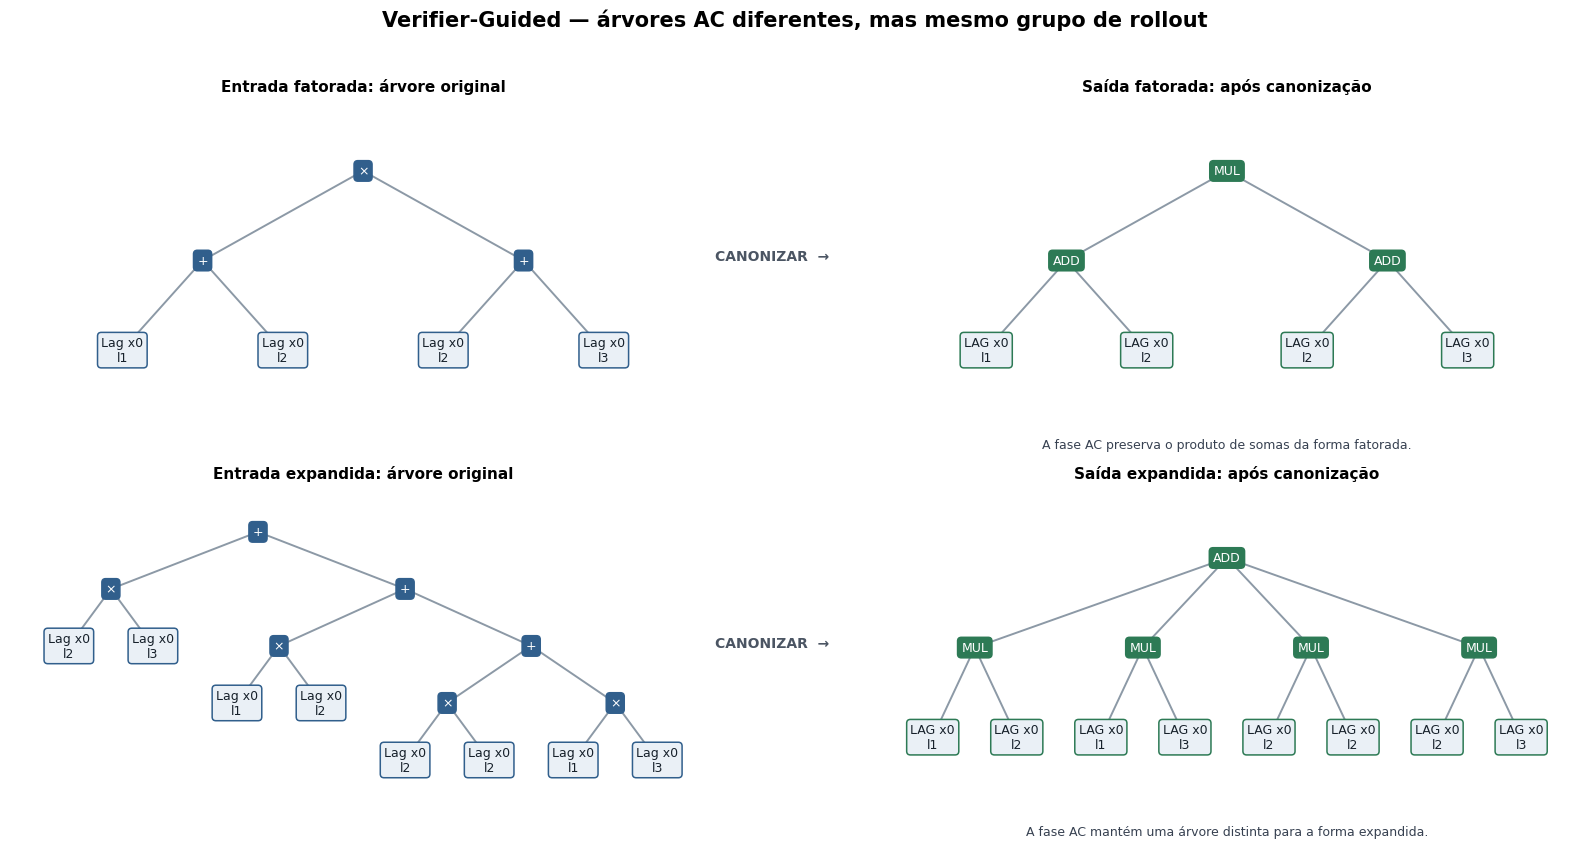

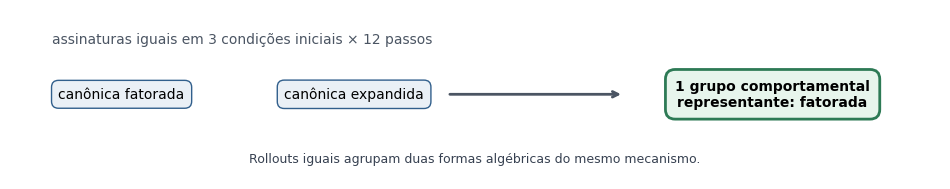

In [11]:
show_transformations(
    [("fatorada", vg_factored), ("expandida", vg_expanded)],
    verifier.canonical_structure,
    "Verifier-Guided — árvores AC diferentes, mas mesmo grupo de rollout",
    captions=[
        "A fase AC preserva o produto de somas da forma fatorada.",
        "A fase AC mantém uma árvore distinta para a forma expandida.",
    ],
)

fig, axis = plt.subplots(figsize=(12, 2.2))
axis.axis("off")
axis.text(0.12, 0.5, "canônica fatorada", ha="center", va="center", bbox=dict(boxstyle="round,pad=0.5", fc="#eaf0f6", ec="#315f8c"))
axis.text(0.37, 0.5, "canônica expandida", ha="center", va="center", bbox=dict(boxstyle="round,pad=0.5", fc="#eaf0f6", ec="#315f8c"))
axis.annotate("", xy=(0.66, 0.5), xytext=(0.47, 0.5), arrowprops=dict(arrowstyle="->", lw=2, color="#4b5563"))
axis.text(0.82, 0.5, "1 grupo comportamental\nrepresentante: fatorada", ha="center", va="center", weight="bold", bbox=dict(boxstyle="round,pad=0.7", fc="#e7f5ec", ec="#2d7a55", lw=2))
axis.text(0.25, 0.82, "assinaturas iguais em 3 condições iniciais × 12 passos", ha="center", va="center", color="#4b5563")
axis.text(0.5, 0.08, "Rollouts iguais agrupam duas formas algébricas do mesmo mecanismo.",
          transform=axis.transAxes, ha="center", va="bottom", fontsize=9, color="#374151")
plt.show()

In [12]:
# Contraexemplo: arredondamento pode unir fórmulas não equivalentes.
base = Lag(0, "l1")
tiny_perturbation = Add(base, Parameter("epsilon"))
collision_candidates = [
    verifier.Candidate("x(t-1)", base, {}, {"l1": 1}),
    verifier.Candidate("x(t-1) + 1e-12", tiny_perturbation, {"epsilon": 1e-12}, {"l1": 1}),
]
collision = verifier.deduplicate_candidates(
    collision_candidates,
    initial_conditions=((0.1, 0.2, 0.3),),
    steps=5,
    decimals=8,
)

pd.DataFrame([
    {
        "chaves simbólicas distintas": len(collision.symbolic_representatives),
        "grupos comportamentais observados": len(collision.behavioral_representatives),
        "interpretação": "falso equivalente sob tolerância: não é prova algébrica",
    }
])

,chaves simbólicas distintas,grupos comportamentais observados,interpretação
0,2,1,falso equivalente sob tolerância: não é prova ...


### Visual — falha por falso equivalente

As duas árvores continuam simbolicamente diferentes, mas a perturbação `1e-12` desaparece quando a assinatura é arredondada para oito casas. A deduplicação comportamental as agrupa incorretamente. Este é um limite fundamental de qualquer equivalência definida apenas por amostras e tolerância.

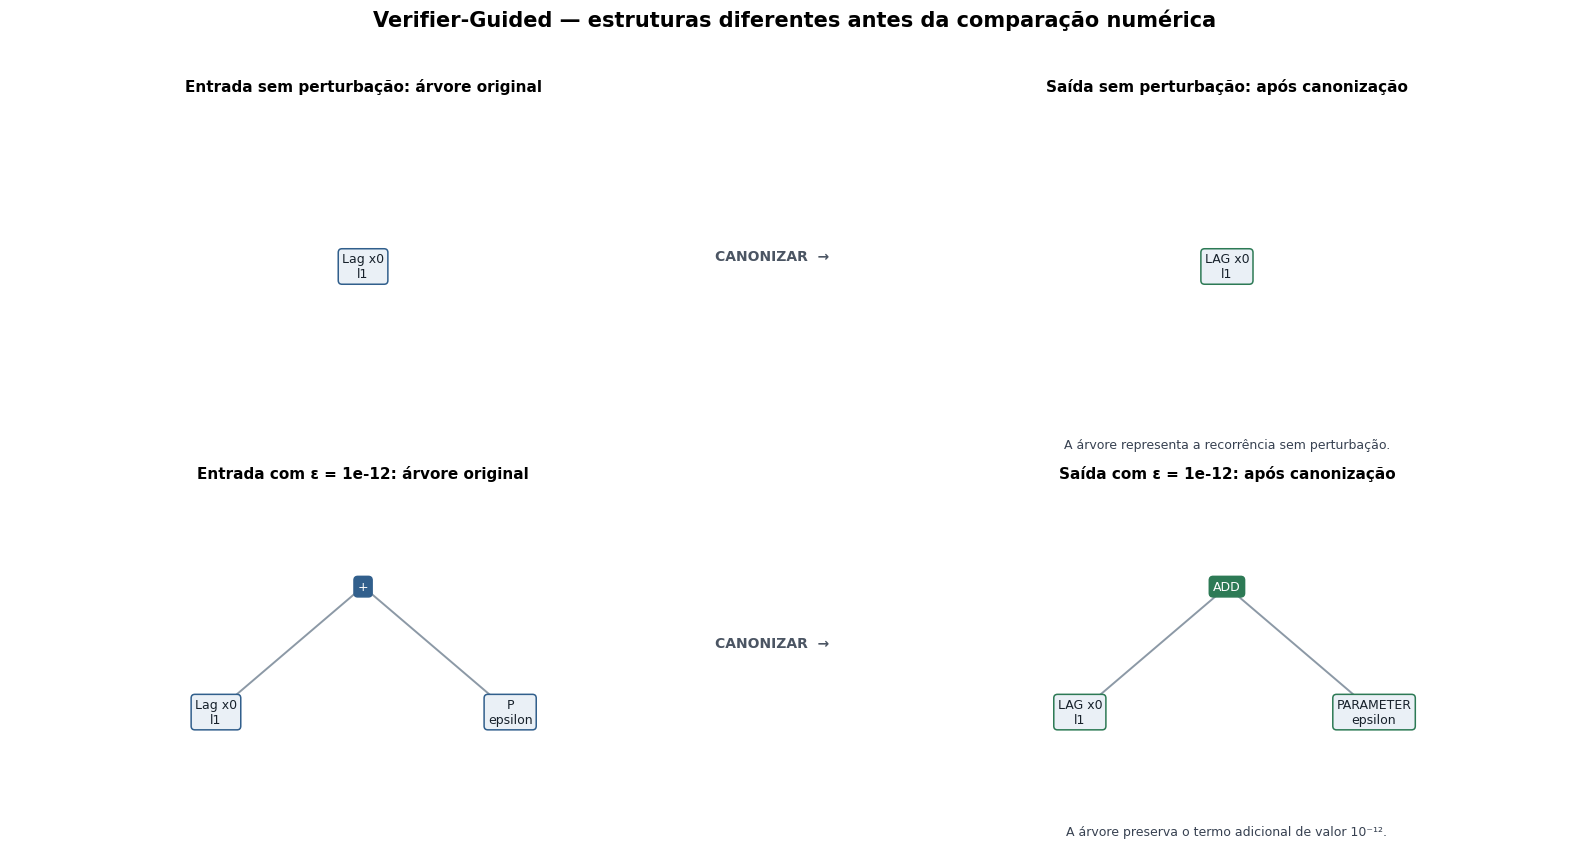

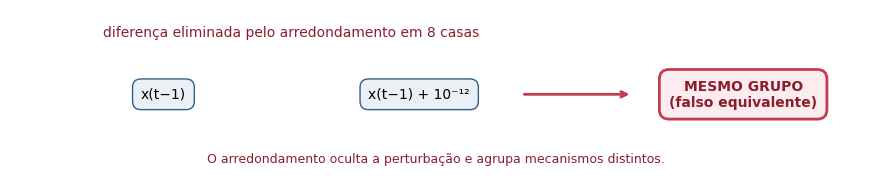

In [13]:
show_transformations(
    [("sem perturbação", base), ("com ε = 1e-12", tiny_perturbation)],
    verifier.canonical_structure,
    "Verifier-Guided — estruturas diferentes antes da comparação numérica",
    captions=[
        "A árvore representa a recorrência sem perturbação.",
        "A árvore preserva o termo adicional de valor 10⁻¹².",
    ],
)

fig, axis = plt.subplots(figsize=(11, 2.2))
axis.axis("off")
axis.text(0.18, 0.5, "x(t−1)", ha="center", va="center", bbox=dict(boxstyle="round,pad=0.6", fc="#eaf0f6", ec="#315f8c"))
axis.text(0.48, 0.5, "x(t−1) + 10⁻¹²", ha="center", va="center", bbox=dict(boxstyle="round,pad=0.6", fc="#eaf0f6", ec="#315f8c"))
axis.annotate("", xy=(0.73, 0.5), xytext=(0.60, 0.5), arrowprops=dict(arrowstyle="->", lw=2, color="#c43d4f"))
axis.text(0.86, 0.5, "MESMO GRUPO\n(falso equivalente)", ha="center", va="center", weight="bold", color="#8b1e2d", bbox=dict(boxstyle="round,pad=0.7", fc="#fdecef", ec="#c43d4f", lw=2))
axis.text(0.33, 0.84, "diferença eliminada pelo arredondamento em 8 casas", ha="center", color="#8b1e2d")
axis.text(0.5, 0.08, "O arredondamento oculta a perturbação e agrupa mecanismos distintos.",
          transform=axis.transAxes, ha="center", va="bottom", fontsize=9, color="#8b1e2d")
plt.show()

**Garantia e limite:** a fase simbólica garante unicidade apenas sob AC para átomos nomeados. A fase comportamental pode unir formas distributivamente equivalentes, como no exemplo complexo, mas também pode produzir falsos equivalentes por cobertura insuficiente, arredondamento, parâmetros específicos ou condições iniciais especiais. Rollouts adicionais reduzem o risco, sem transformá-lo em prova.

### Produto de três variáveis com \(+x_0\) — soma preservada na fase simbólica

Aplicamos a chave associativo-comutativa às mesmas entradas A, B e C. A multiplicação encadeada vira um único MUL com os fatores ordenados \(x_0,x_1,x_2\). A raiz ADD reúne o \(x_0\) isolado e esse produto; o lag vem primeiro pela ordem das chaves LAG e MUL. A igualdade das três variantes já é reconhecida pela fase simbólica.

Este exemplo usa três séries na canonização estrutural. Os testes de rollout acima usam o avaliador escalar da implementação; aqui comparamos apenas as árvores e suas chaves.

,Fórmula,Lista da saída,Mesma árvore de A?
Entrada,,,
A,((x_0 × x_1) × x_2) + x_0,"['ADD', 'x_0', ['MUL', 'x_0', 'x_1', 'x_2']]",True
B,(x_2 × (x_1 × x_0)) + x_0,"['ADD', 'x_0', ['MUL', 'x_0', 'x_1', 'x_2']]",True
C,(x_0 × (x_1 × x_2)) + x_0,"['ADD', 'x_0', ['MUL', 'x_0', 'x_1', 'x_2']]",True


3 entradas → 1 chave simbólica; este exemplo dispensa rollouts.


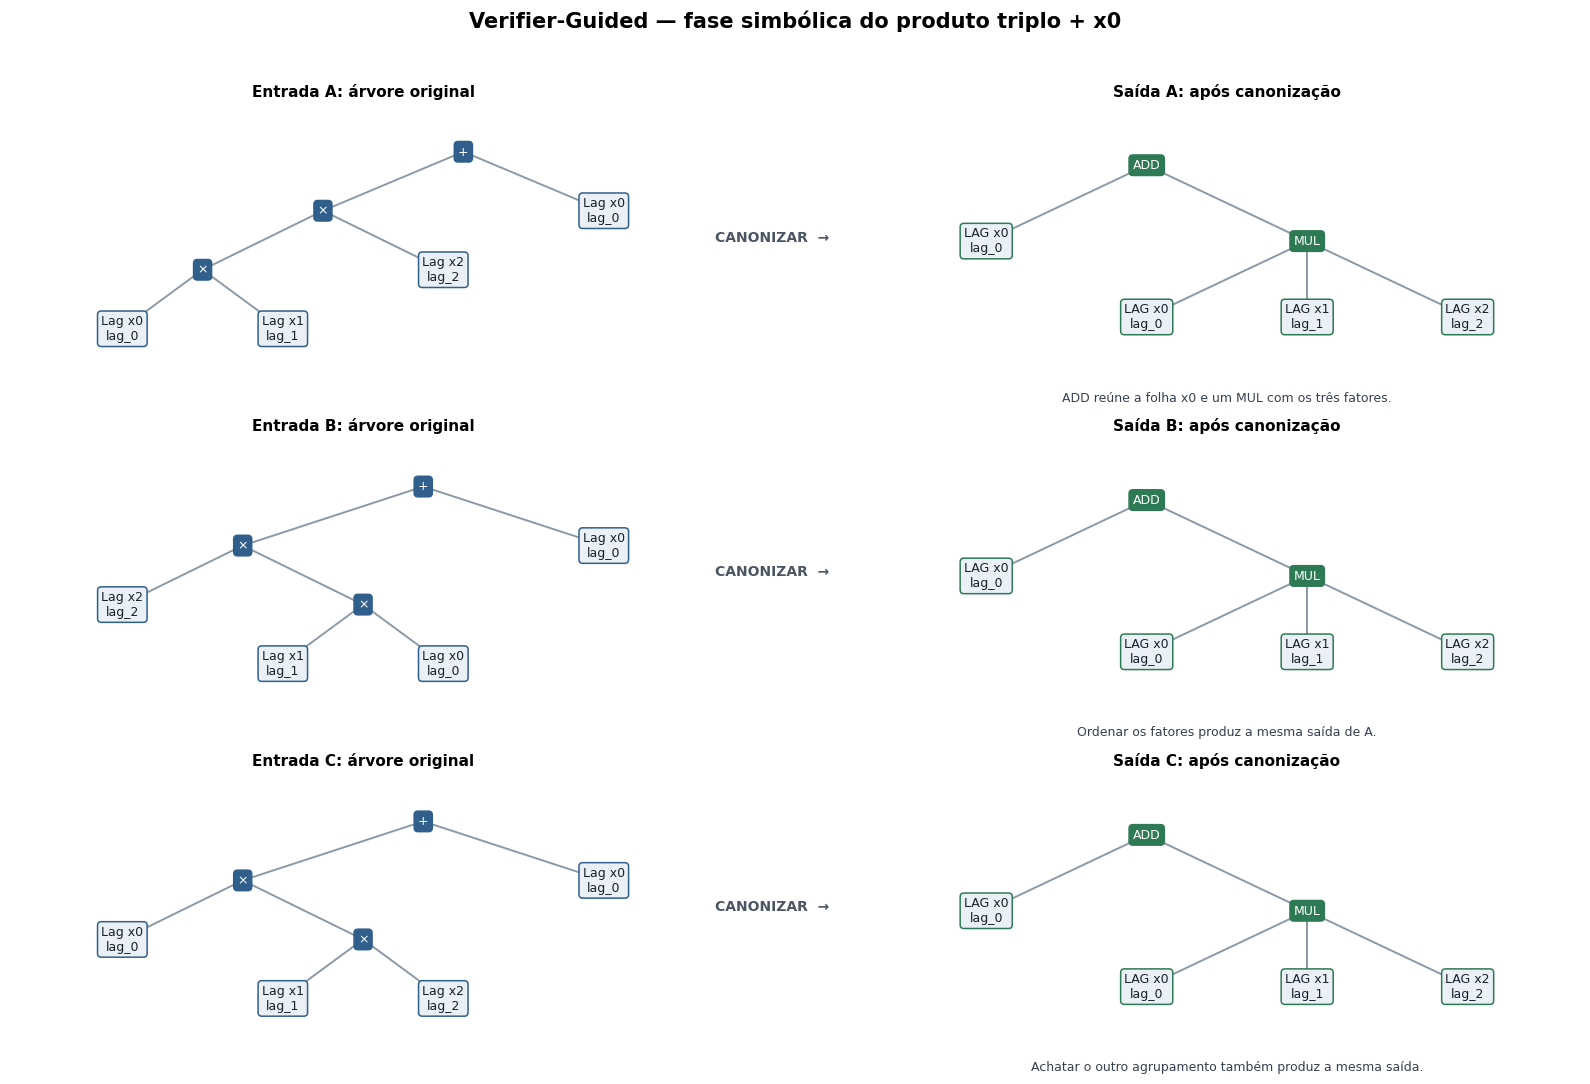

,"Árvores distintas entre A, B e C",Estrutura da saída de A
Técnica,,
CCBL,2,"['ADD', 'x_0', ['MUL', 'x_2', ['MUL', 'x_0', 'x_1']]]"
SimpliPy restrito,1,"['ADD', ['MUL', 'x_0'], ['MUL', 'x_0', 'x_1', 'x_2']]"
Verifier-Guided: fase simbólica,1,"['ADD', 'x_0', ['MUL', 'x_0', 'x_1', 'x_2']]"


In [19]:
triple_verifier_keys = {
    label: verifier.canonical_key(tree) for label, tree in triple_variants.items()
}
triple_verifier_lists = {
    label: triple_list_for_display(verifier.canonical_structure(tree))
    for label, tree in triple_variants.items()
}
triple_verifier_expected = ["ADD", "x_0", ["MUL", "x_0", "x_1", "x_2"]]
assert len(set(triple_verifier_keys.values())) == 1
assert all(value == triple_verifier_expected
           for value in triple_verifier_lists.values())

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame([
        {"Entrada": label, "Fórmula": triple_formulas[label],
         "Lista da saída": repr(triple_verifier_lists[label]),
         "Mesma árvore de A?": triple_verifier_keys[label] == triple_verifier_keys["A"]}
        for label in triple_variants
    ]).set_index("Entrada"))
print("3 entradas → 1 chave simbólica; este exemplo dispensa rollouts.")

show_transformations(
    list(triple_variants.items()), verifier.canonical_structure,
    "Verifier-Guided — fase simbólica do produto triplo + x0",
    captions=[
        "ADD reúne a folha x0 e um MUL com os três fatores.",
        "Ordenar os fatores produz a mesma saída de A.",
        "Achatar o outro agrupamento também produz a mesma saída.",
    ],
    figsize=(16, 11),
)

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame([
        {"Técnica": "CCBL", "Árvores distintas entre A, B e C": len(set(triple_ccbl_keys.values())),
         "Estrutura da saída de A": repr(triple_ccbl_lists["A"])},
        {"Técnica": "SimpliPy restrito",
         "Árvores distintas entre A, B e C": len(set(triple_simplipy_keys.values())),
         "Estrutura da saída de A": repr(triple_simplipy_lists["A"])},
        {"Técnica": "Verifier-Guided: fase simbólica",
         "Árvores distintas entre A, B e C": len(set(triple_verifier_keys.values())),
         "Estrutura da saída de A": repr(triple_verifier_lists["A"])},
    ]).set_index("Técnica"))

**O que a célula fez.** Verificou que A, B e C possuem a mesma chave e desenhou a soma de \(x_0\) com um produto de três fatores. A tabela final compara as saídas como listas **aninhadas**: a CCBL mantém a soma e dois produtos binários; o SimpliPy restrito coloca cada parcela em um MUL, incluindo o \(x_0\) isolado; a fase simbólica Verifier-Guided deixa esse \(x_0\) diretamente como filho de ADD e achata o produto triplo. O exemplo evidencia a diferença entre a forma de soma de produtos e a árvore associativo-comutativa. Expressões com operações e funções alternadas podem ter mais níveis. As igualdades verificadas são simbólicas; reagrupar operações em ponto flutuante pode introduzir pequenas diferenças numéricas.

## 4. Desempenho da canonização por cenário e tamanho de árvore

O benchmark mede somente a construção da chave canônica para tornar os três tempos comparáveis. A simulação Verifier-Guided é uma etapa posterior e seu custo depende do número de rollouts e do horizonte; uma medição separada aparece depois da tabela principal. Cada ponto usa uma chamada de aquecimento e a mediana de 7 execuções.

In [14]:
BENCHMARK_REPEATS = 7
MAX_TERMS = 4096


def add_chain(term_count: int):
    return reduce(Add, [Lag(0, f"A{i}") for i in range(term_count)])


def median_milliseconds(function, repeats: int = BENCHMARK_REPEATS):
    try:
        function()  # warm-up
        durations = []
        for _ in range(repeats):
            start = perf_counter()
            function()
            durations.append((perf_counter() - start) * 1000)
        return float(np.median(durations)), "ok"
    except simplipy.ExpansionLimitError as error:
        return np.nan, str(error)


benchmark_cases = []
for terms in (4, 8, 16, 32, 64, 128):
    benchmark_cases.append(("cadeia de somas (AC)", terms, add_chain(terms)))
for factors in (2, 4, 6, 8, 10, 12, 13):
    benchmark_cases.append(("produto de somas (distributivo)", factors, product_of_sums(factors)))

benchmark_rows = []
for scenario, scale, expression in benchmark_cases:
    ccbl_ms, ccbl_status = median_milliseconds(lambda e=expression: ccbl.canonical_key(e))
    simplipy_ms, simplipy_status = median_milliseconds(
        lambda e=expression: simplipy.canonical_key(e, max_terms=MAX_TERMS)
    )
    verifier_ms, verifier_status = median_milliseconds(lambda e=expression: verifier.canonical_key(e))
    benchmark_rows.append({
        "cenário": scenario,
        "escala": scale,
        "nós": node_count(expression),
        "CCBL (ms)": ccbl_ms,
        "SimpliPy restrito (ms)": simplipy_ms,
        "Verifier AC (ms)": verifier_ms,
        "status SimpliPy": simplipy_status,
    })

benchmark = pd.DataFrame(benchmark_rows)
benchmark.round(4)

,cenário,escala,nós,CCBL (ms),SimpliPy restrito (ms),Verifier AC (ms),status SimpliPy
0,cadeia de somas (AC),4,7,0.0263,0.0324,0.0064,ok
1,cadeia de somas (AC),8,15,0.0704,0.0638,0.0104,ok
2,cadeia de somas (AC),16,31,0.2163,0.1445,0.0202,ok
3,cadeia de somas (AC),32,63,0.7515,0.3166,0.0393,ok
4,cadeia de somas (AC),64,127,2.7625,0.4137,0.0412,ok
5,cadeia de somas (AC),128,255,7.4005,0.8099,0.1069,ok
6,produto de somas (distributivo),2,7,0.0238,0.0436,0.0092,ok
7,produto de somas (distributivo),4,15,0.0601,0.2153,0.0171,ok
8,produto de somas (distributivo),6,23,0.1062,1.2591,0.0249,ok
9,produto de somas (distributivo),8,31,0.1611,6.5245,0.0330,ok


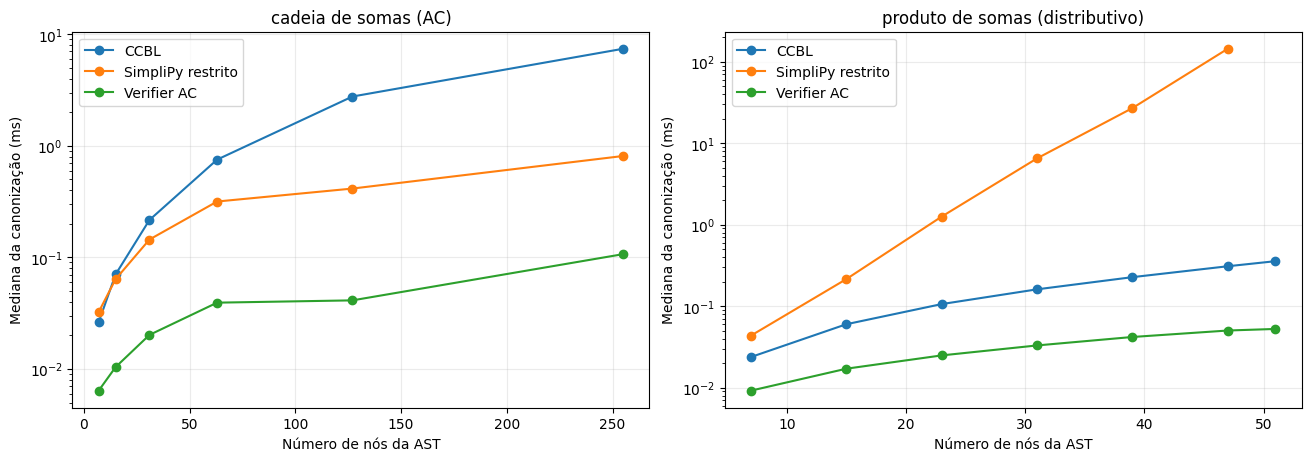

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for axis, (scenario, group) in zip(axes, benchmark.groupby("cenário", sort=False)):
    for column, label in (
        ("CCBL (ms)", "CCBL"),
        ("SimpliPy restrito (ms)", "SimpliPy restrito"),
        ("Verifier AC (ms)", "Verifier AC"),
    ):
        axis.plot(group["nós"], group[column], marker="o", label=label)
    axis.set_title(scenario)
    axis.set_xlabel("Número de nós da AST")
    axis.set_ylabel("Mediana da canonização (ms)")
    axis.set_yscale("log")
    axis.grid(alpha=0.25)
    axis.legend()
plt.show()

In [16]:
# Custo adicional ilustrativo do rollout, fora do tempo de canonização.
rollout_rows = []
for factors in (2, 4, 6, 8, 10, 12):
    expression = product_of_sums(factors)
    lags = {f"L{i}": (i % 3) + 1 for i in range(2 * factors)}
    rollout_ms, status = median_milliseconds(
        lambda e=expression, b=lags: verifier.rollout_signature(
            e,
            parameter_values={},
            lag_values=b,
            initial_conditions=((0.01, 0.02, 0.03), (-0.03, 0.02, 0.01), (0.04, -0.01, 0.02)),
            steps=12,
            decimals=10,
        ),
        repeats=3,
    )
    rollout_rows.append({"fatores": factors, "nós": node_count(expression), "rollout (ms)": rollout_ms, "status": status})

pd.DataFrame(rollout_rows).round(4)

,fatores,nós,rollout (ms),status
0,2,7,0.2277,ok
1,4,15,0.4322,ok
2,6,23,0.6408,ok
3,8,31,0.9281,ok
4,10,39,1.0634,ok
5,12,47,1.2698,ok


## Conclusão

- A CCBL é adequada como ordenação local barata, mas não entrega unicidade AC porque mantém a parentização.
- A forma normal restrita inspirada em SimpliPy fornece a garantia mais forte neste vocabulário: unicidade para o fragmento de semianel módulo associatividade, comutatividade e distributividade, desde que os slots nomeados coincidam e a expansão permaneça abaixo do limite.
- O fluxo Verifier-Guided complementa a chave simbólica com evidência executável e consegue juntar algumas fórmulas que a chave AC separa. Sua equivalência é necessariamente condicionada aos bindings, condições iniciais, horizonte e tolerância.
- A tabela evidencia o custo da garantia mais forte: em produtos de somas, a forma polinomial acompanha o número exponencial de monômios, enquanto as chaves estruturais acompanham principalmente o tamanho da AST de entrada.

## Registro completo do experimento

**Pergunta de pesquisa.** Até onde três estratégias — CCBL, normalização restrita inspirada em SimpliPy/Flash-ANSR e pooling inspirado em Verifier-Guided Discovery — reconhecem fórmulas equivalentes no vocabulário atual, e qual é o custo temporal conforme a árvore cresce?

**Hipótese.** A CCBL reconhecerá somente trocas comutativas locais; a normalização polinomial reconhecerá AC e distributividade com custo potencialmente exponencial; a verificação por rollout reconhecerá equivalências adicionais, mas sem garantia global.

**Configuração completa.** Vocabulário: `Parameter`, `Time`, `Lag`, `Add`, `Multiply`, `Tanh`. SimpliPy restrito: `max_terms=4096`, slots tratados como átomos semânticos e `Tanh` opaca após normalização recursiva. Verifier-Guided: chave AC; rollouts principais com 3 condições iniciais, horizonte 12, arredondamento em 10 casas e recorrência escalar; contraexemplo com horizonte 5 e 8 casas. Visualização: diagramas lado a lado `árvore original → árvore após canonização`, com operadores em azul/verde, falhas em vermelho e uma visualização separada dos grupos comportamentais. Benchmark: cenários cadeia de somas com 4, 8, 16, 32, 64 e 128 termos; produto de somas com 2, 4, 6, 8, 10, 12 e 13 fatores; 1 aquecimento e mediana de 7 repetições. O custo adicional de rollout usa 3 repetições, 3 condições iniciais e horizonte 12.

**Proveniência e manifesto.** Repositório `tsfmxai`, commit-base `837dd88b6cfd07ae6f57ad9bfe8da6a2f753e2e5` com árvore de trabalho já modificada; Python 3.11.9; Windows 10. Fontes metodológicas: Saegert e Köthe (2026), *Breaking the Simplification Bottleneck in Amortized Neural Symbolic Regression*, arXiv:2602.08885; Faraji e Belardinelli (2026), *Verifier-Guided Model Discovery for Physical Dynamical Systems with Pretrained Symbolic Transformers*, arXiv:2608.02662. Implementações avaliadas: `binary_local_commutative/canonicalizer.py`, `simplipy_flash_ansr/canonicalizer.py` e `verifier_guided/canonicalizer.py`.

**Sementes.** Nenhuma aleatoriedade é usada: árvores, bindings e condições iniciais são determinísticos. Portanto, não há semente pseudoaleatória a registrar.

**Exemplos CCBL e atualização visual.** As entradas A, B, C e D são quatro permutações locais de `(t*x)+(p+y)` com a mesma árvore CCBL. E usa `((t*x)+p)+y`, preserva a fórmula e produz outra árvore. O notebook verifica as cinco identidades pela forma polinomial com slots nomeados e compara as árvores CCBL por igualdade estrutural. A tabela e três figuras apresentam esses resultados; cada saída mantém uma legenda de uma linha. A ampliação preserva os demais resultados e tempos de benchmark registrados.

**Produto triplo com parcela adicional (exemplo atualizado a pedido).** A=((x_0*x_1)*x_2)+x_0, B=(x_2*(x_1*x_0))+x_0, C=(x_0*(x_1*x_2))+x_0, com x_j=X_j(t-1), séries j=0,1,2 e slots lag_0,lag_1,lag_2 ligados ao atraso 1. As duas ocorrências de x_0 representam a mesma variável e atraso. A forma polinomial verifica a identidade das três entradas; asserts verificam as chaves e listas esperadas. Para essas três variantes, a CCBL produz duas árvores distintas; SimpliPy restrito e a fase simbólica Verifier-Guided produzem uma cada. SimpliPy representa o termo isolado como MUL(x_0); Verifier-Guided o mantém como uma folha sob ADD. Três tabelas, três figuras e uma comparação final mostram as estruturas e suas listas abreviadas. O exemplo Verifier-Guided usa apenas a fase simbólica multivariada. As demais células e medições foram preservadas.

**Métricas.** Igualdade das chaves nos exemplos positivos e negativos; inspeção visual das árvores antes/depois; número de representantes após deduplicação simbólica e comportamental; mediana do tempo de canonização em milissegundos; custo adicional do rollout em milissegundos; ocorrência do limite de expansão.

**Resumo científico.** Os resultados salvos confirmam a hipótese. A CCBL não identifica associatividade ou distributividade. A forma polinomial restrita dá uma chave única no fragmento declarado e iguala um exemplo complexo fatorado/expandido, mas atinge o limite no crescimento exponencial. O método Verifier-Guided agrupa por rollout as variantes distributivas, porém o contraexemplo de perturbação demonstra um falso equivalente induzido pela tolerância. Logo, unicidade algébrica e equivalência comportamental devem permanecer métricas distintas.

**Reprodução exata a partir da raiz do repositório.**  
`./.venv/Scripts/python.exe -m jupyter nbconvert --to notebook --execute --inplace experiments/canonicalization/00_canonicalization_comparison.ipynb --ExecutePreprocessor.timeout=600`
